# Predicción de la impuntualidad en una ruta de transporte público de Cusco
## Notebook de la entrega final

**Curso:** 1INF02 Aprendizaje de Máquina — 2026-2 (PUCP) · **Grupo 06:** Jafeth Manases Cuyo Alata, Raul Esteban Herrera Guerrero, Matias Esteban Marrufo Zapata

Este notebook continúa el del Entregable 2 (`Notebooks E2/AM2026_2_Experimentacion.ipynb`) y documenta las mejoras de la entrega final.
El código está en módulos `.py` de esta carpeta para que cada paso se pueda leer y probar por separado:

| Módulo | Contenido |
|---|---|
| `prep.py` | Limpieza, variables F0/F1/F2 y partición temporal (idénticas a E2) + grupos nuevos C, A y P |
| `modelos.py` | Modelos, Pipeline y métricas (E2 + exactitud, exactitud balanceada, sensibilidad/especificidad) |
| `cribado.py` | Cribado de los grupos de variables nuevos (solo validación cruzada) |
| `experimento.py` | Búsqueda en malla con validación cruzada temporal (malla ampliada de XGBoost; umbrales −1/+5 y −3/+10) |
| `evaluacion.py` | Selección por validación, evaluación única en prueba, pruebas estadísticas, pesos por clase, importancia |
| `figuras_eda.py`, `figuras_resultados.py` | Gráficos de la presentación (incluye SHAP) |

Las reglas de decisión se fijaron **antes** de ver resultados nuevos en `PROTOCOLO.md`.

**Ejecución local:** colocar `Times.csv` y `Monitoring.csv` en `Dataset/` (o definir `DATA_DIR`). La búsqueda en malla tarda ~1 h con 8 núcleos; si `resultados/cv_raw.csv` existe, se reutiliza.

In [1]:
import os, sys, json, platform
import numpy as np, pandas as pd
import sklearn, xgboost, shap, matplotlib
from IPython.display import Image, display, Markdown
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
print("python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__,
      "| xgboost", xgboost.__version__, "| shap", shap.__version__, "| matplotlib", matplotlib.__version__)
R = lambda f: pd.read_csv(os.path.join("resultados", f))
FIG = lambda f: display(Image(os.path.join("fig", f), width=900))

C:\Users\USUARIO\AppData\Local\Temp\claude\ef83d090f5708062\156870e7-0a1c-4ed0-9ffd-66a060280e63\scratchpad\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


python 3.13.14 | pandas 2.2.3 | numpy 2.4.6 | scikit-learn 1.6.1 | xgboost 3.4.1 | shap 0.54.1 | matplotlib 3.10.0


## 1. Datos y partición (sin cambios respecto de E2)

`prep.cargar()` reproduce la limpieza del Entregable 2 y verifica con `assert` las mismas cifras: 4 707 → 4 559 → 4 004 vueltas,
758 de prueba (28/01–01/02, **incluye el sábado 01/02**), 3 246 de desarrollo y los mismos 4 pliegues de ventana expansiva.

In [2]:
from prep import cargar
d = cargar()
print("vueltas de modelado:", len(d["vm"]), "| desarrollo:", len(d["IDX_DEV"]), "| prueba:", len(d["IDX_TEST"]))
print("pliegues (entrenamiento/validación):", [(len(a), len(b)) for a, b in d["FOLDS"]])

vueltas de modelado: 4004 | desarrollo: 3246 | prueba: 758
pliegues (entrenamiento/validación): [(1503, 451), (1954, 377), (2331, 505), (2836, 410)]


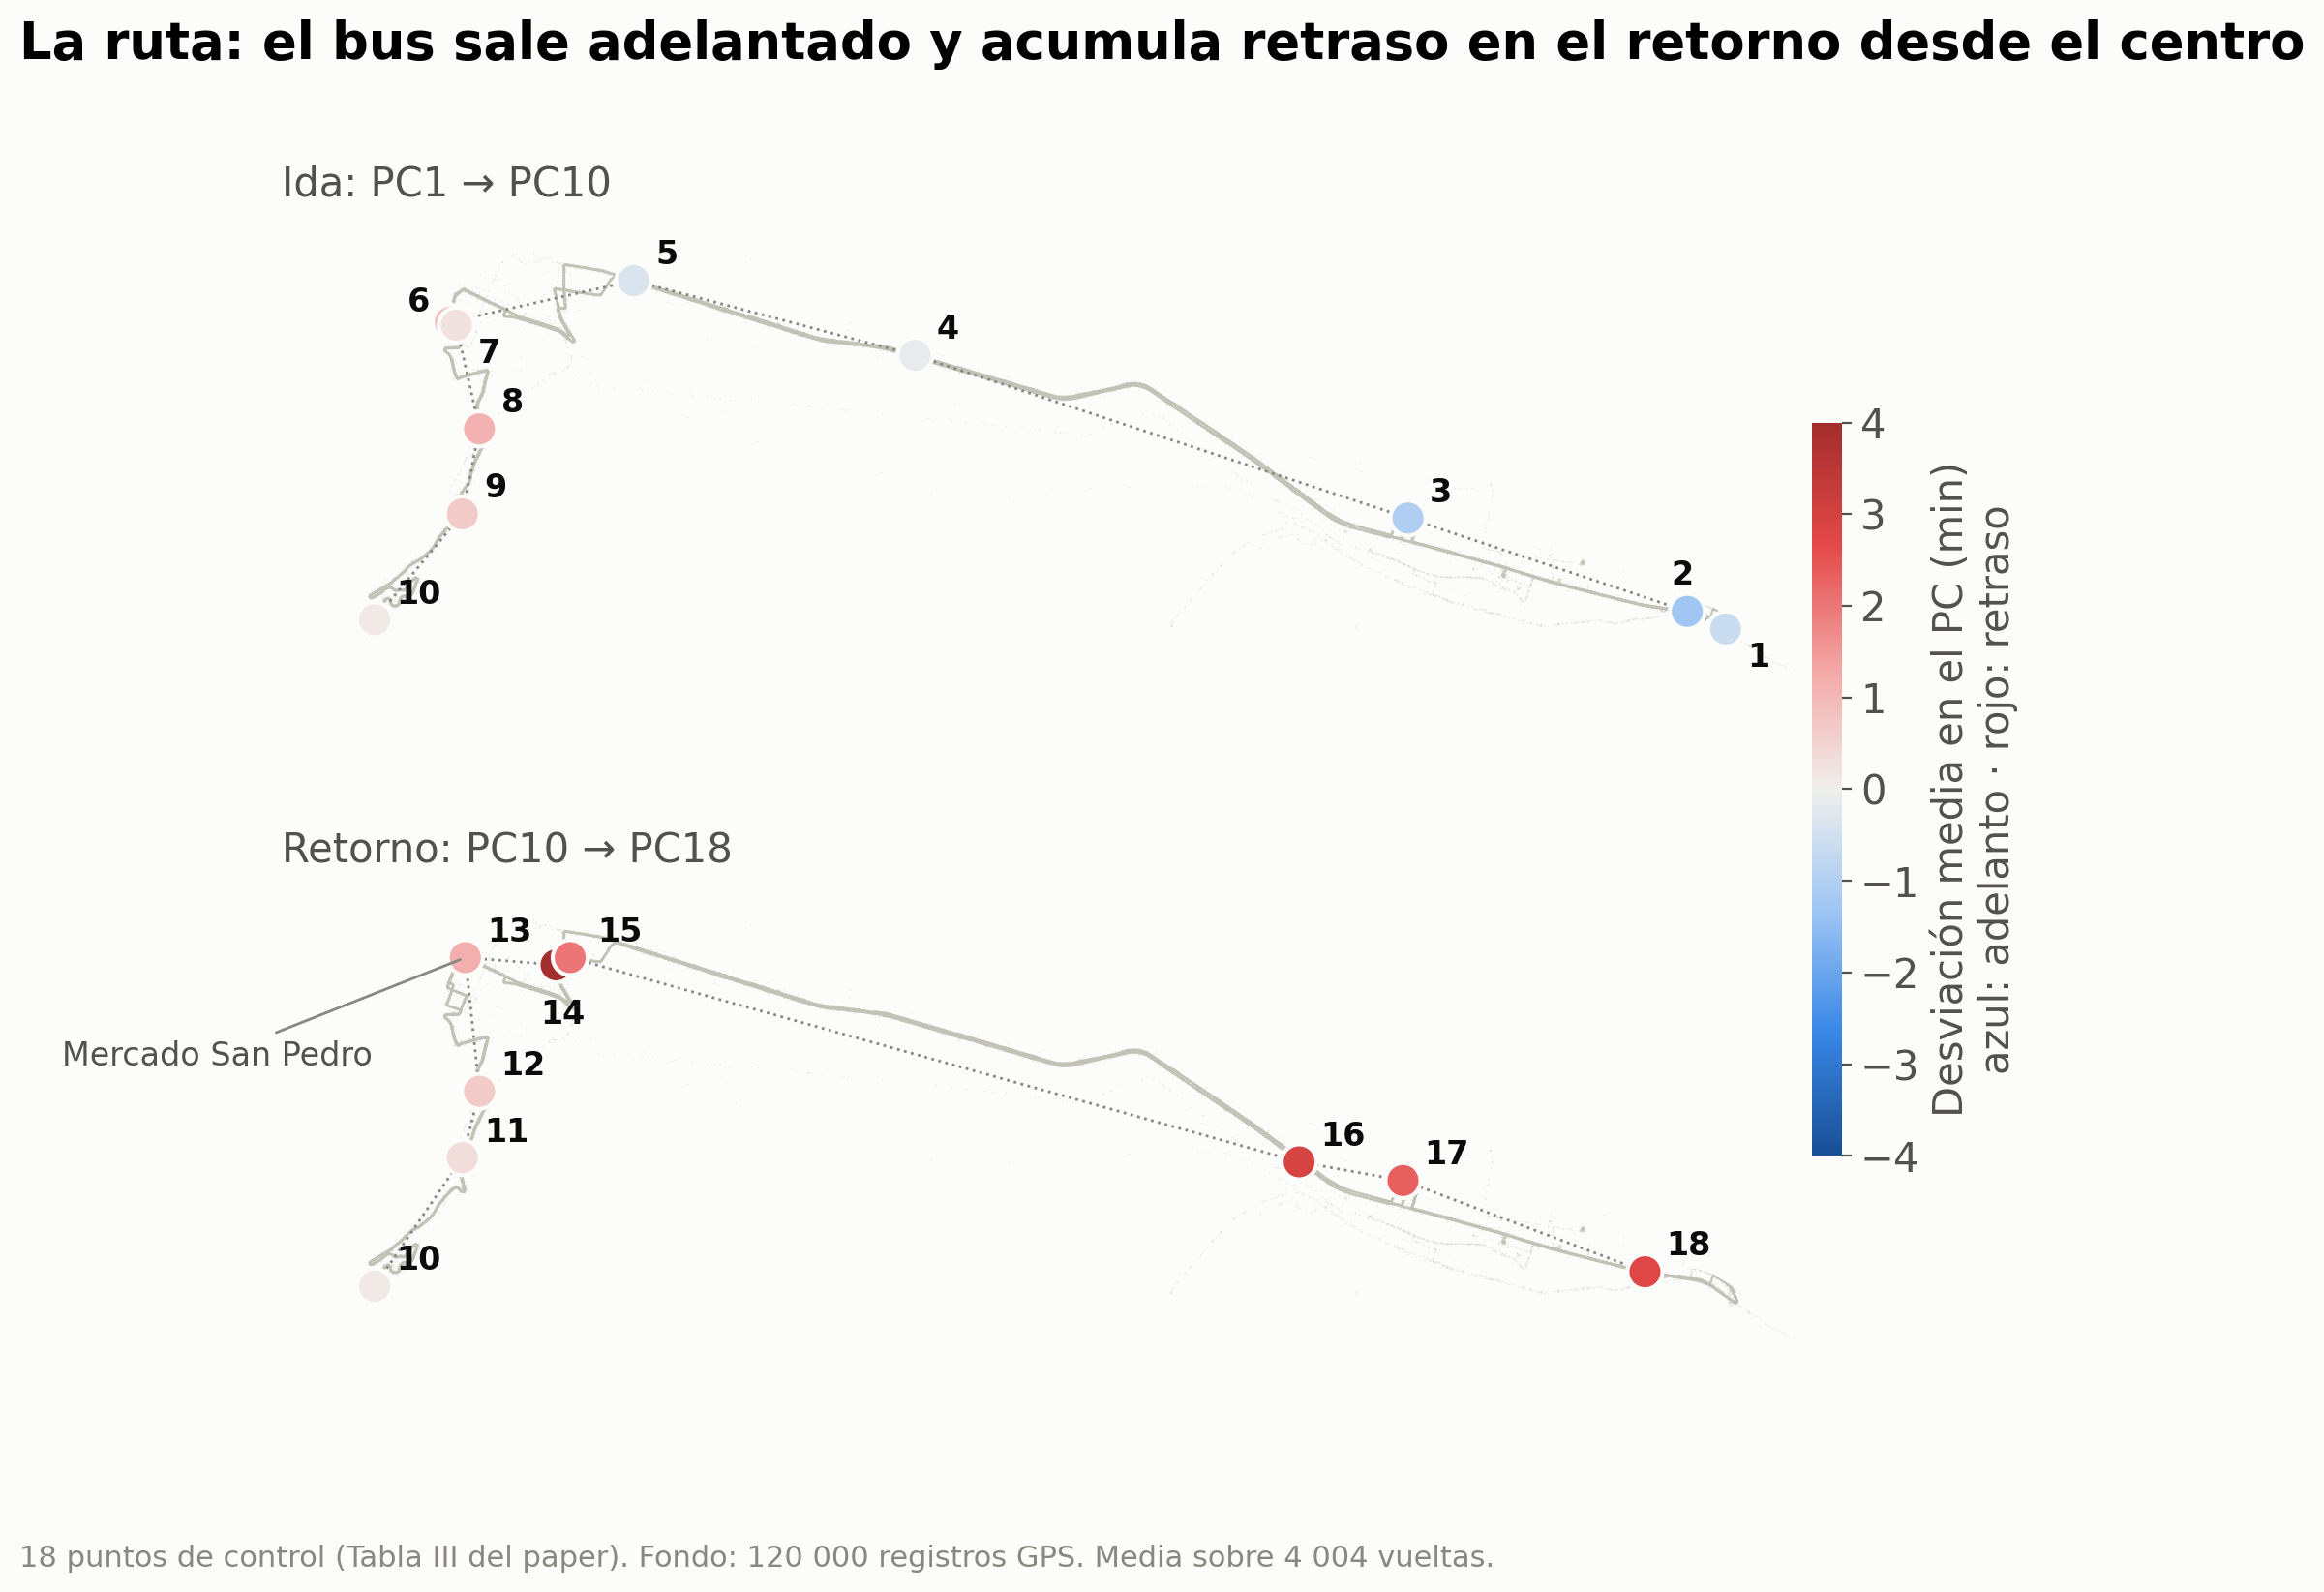

In [3]:
FIG("pres_01_mapa_ruta.png")

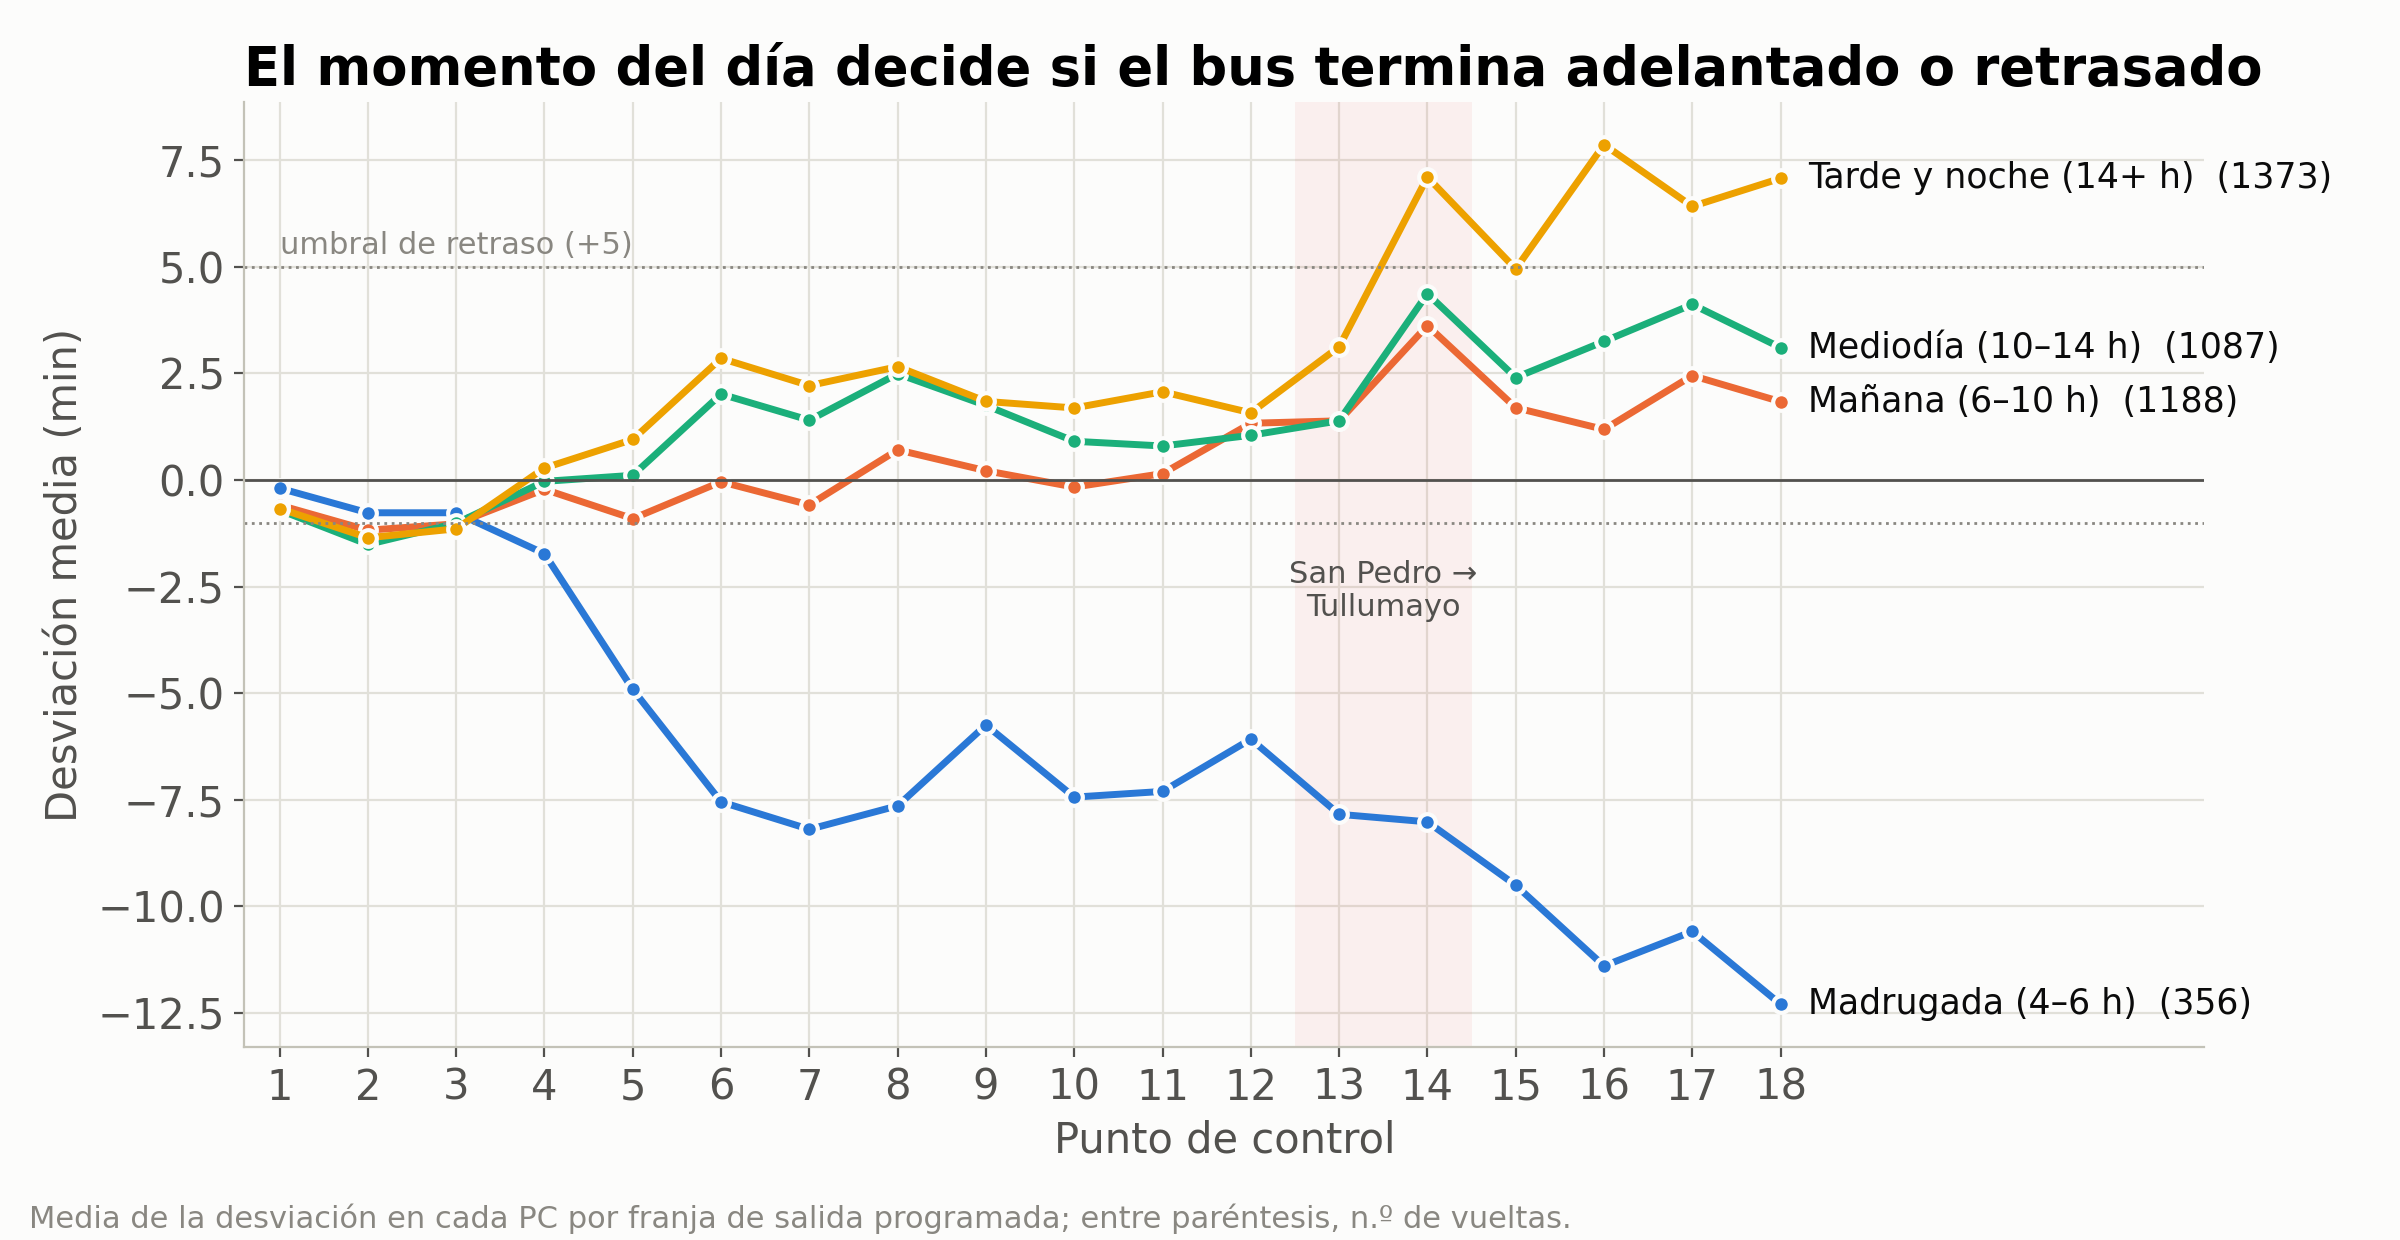

In [4]:
FIG("pres_02_perfil_franja.png")

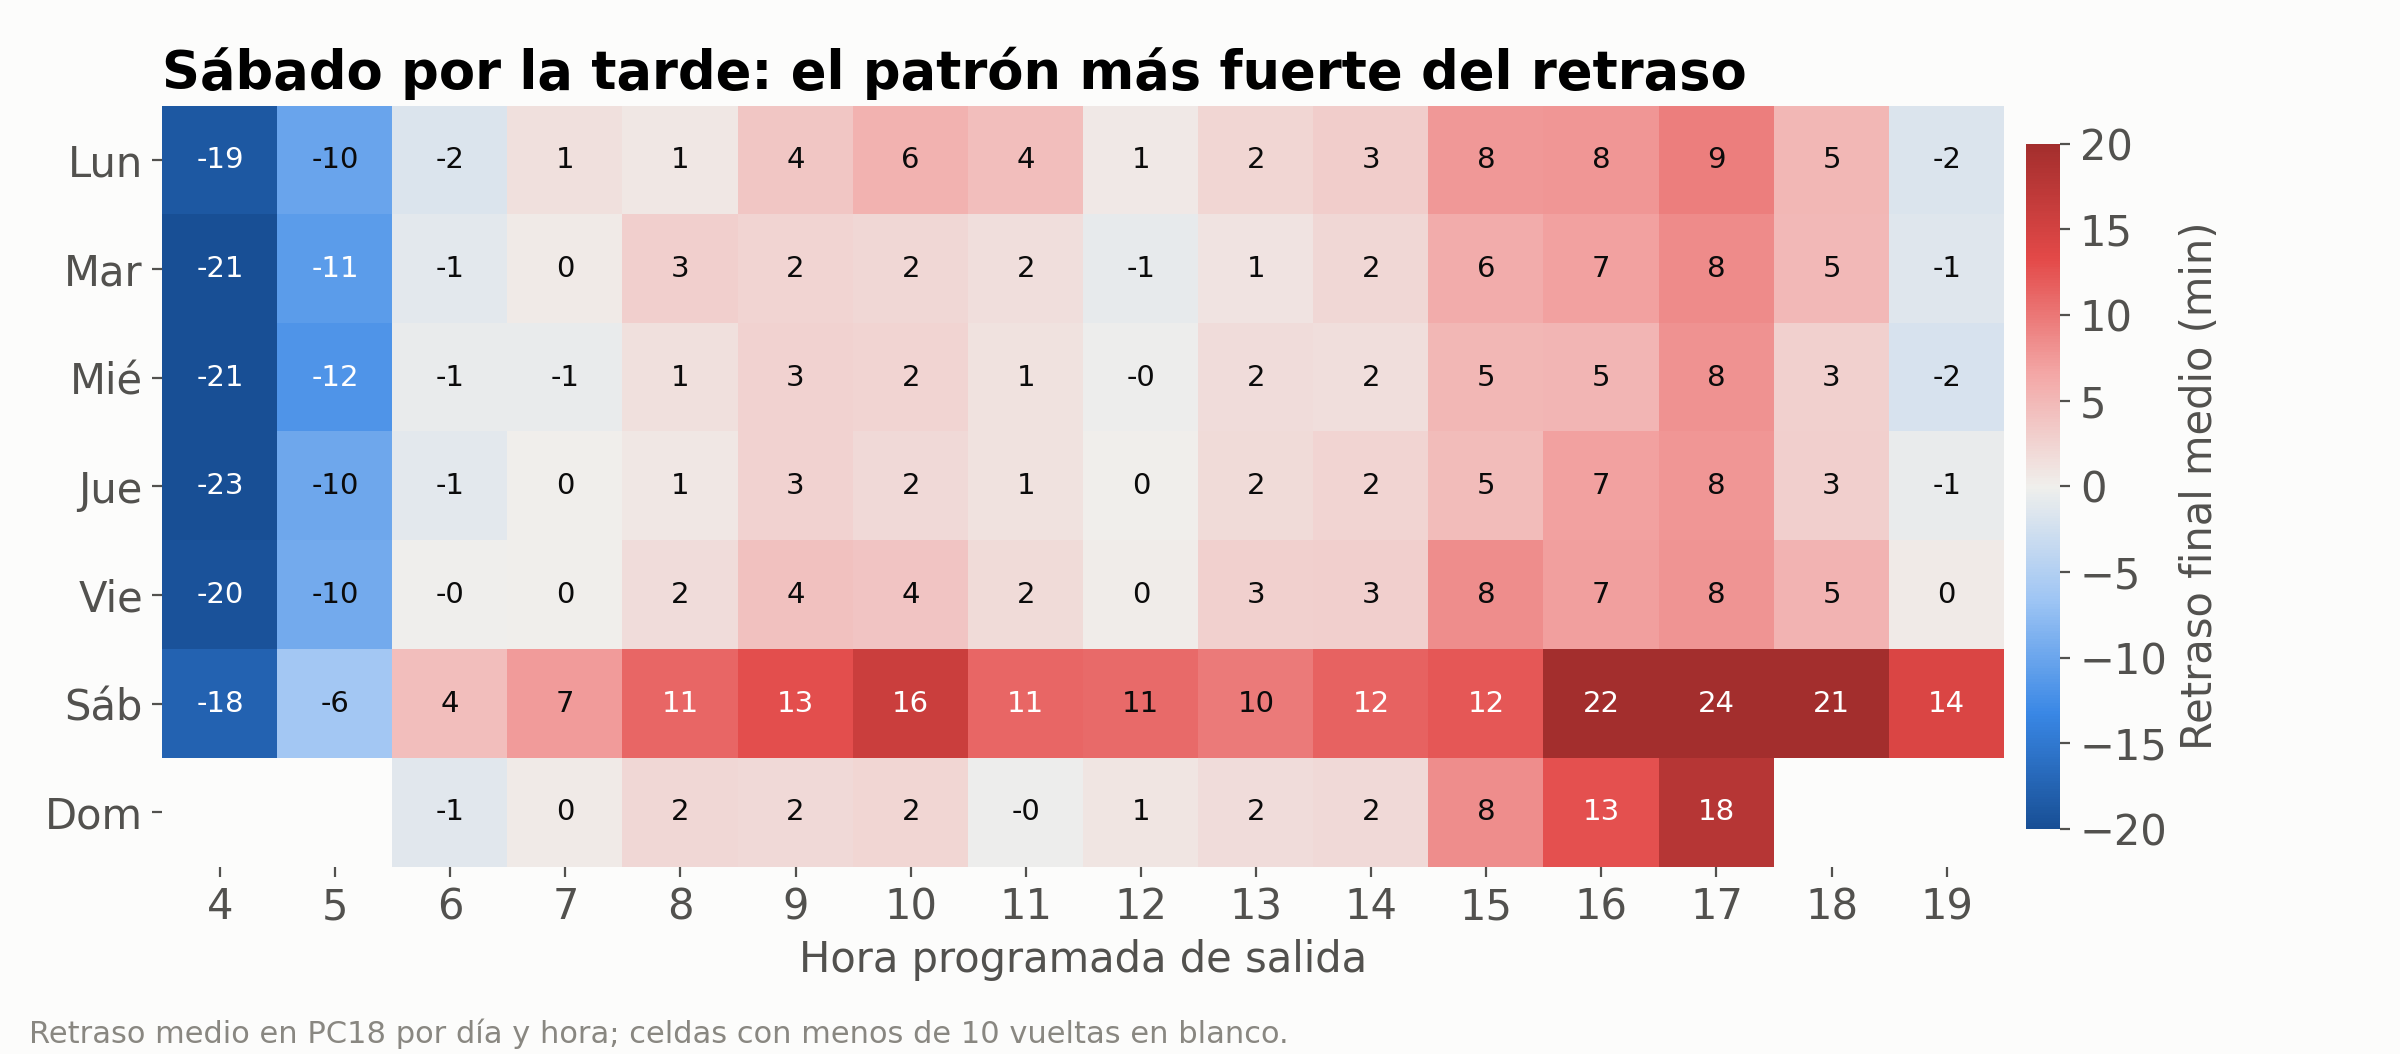

In [5]:
FIG("pres_03_calor_hora_dia.png")

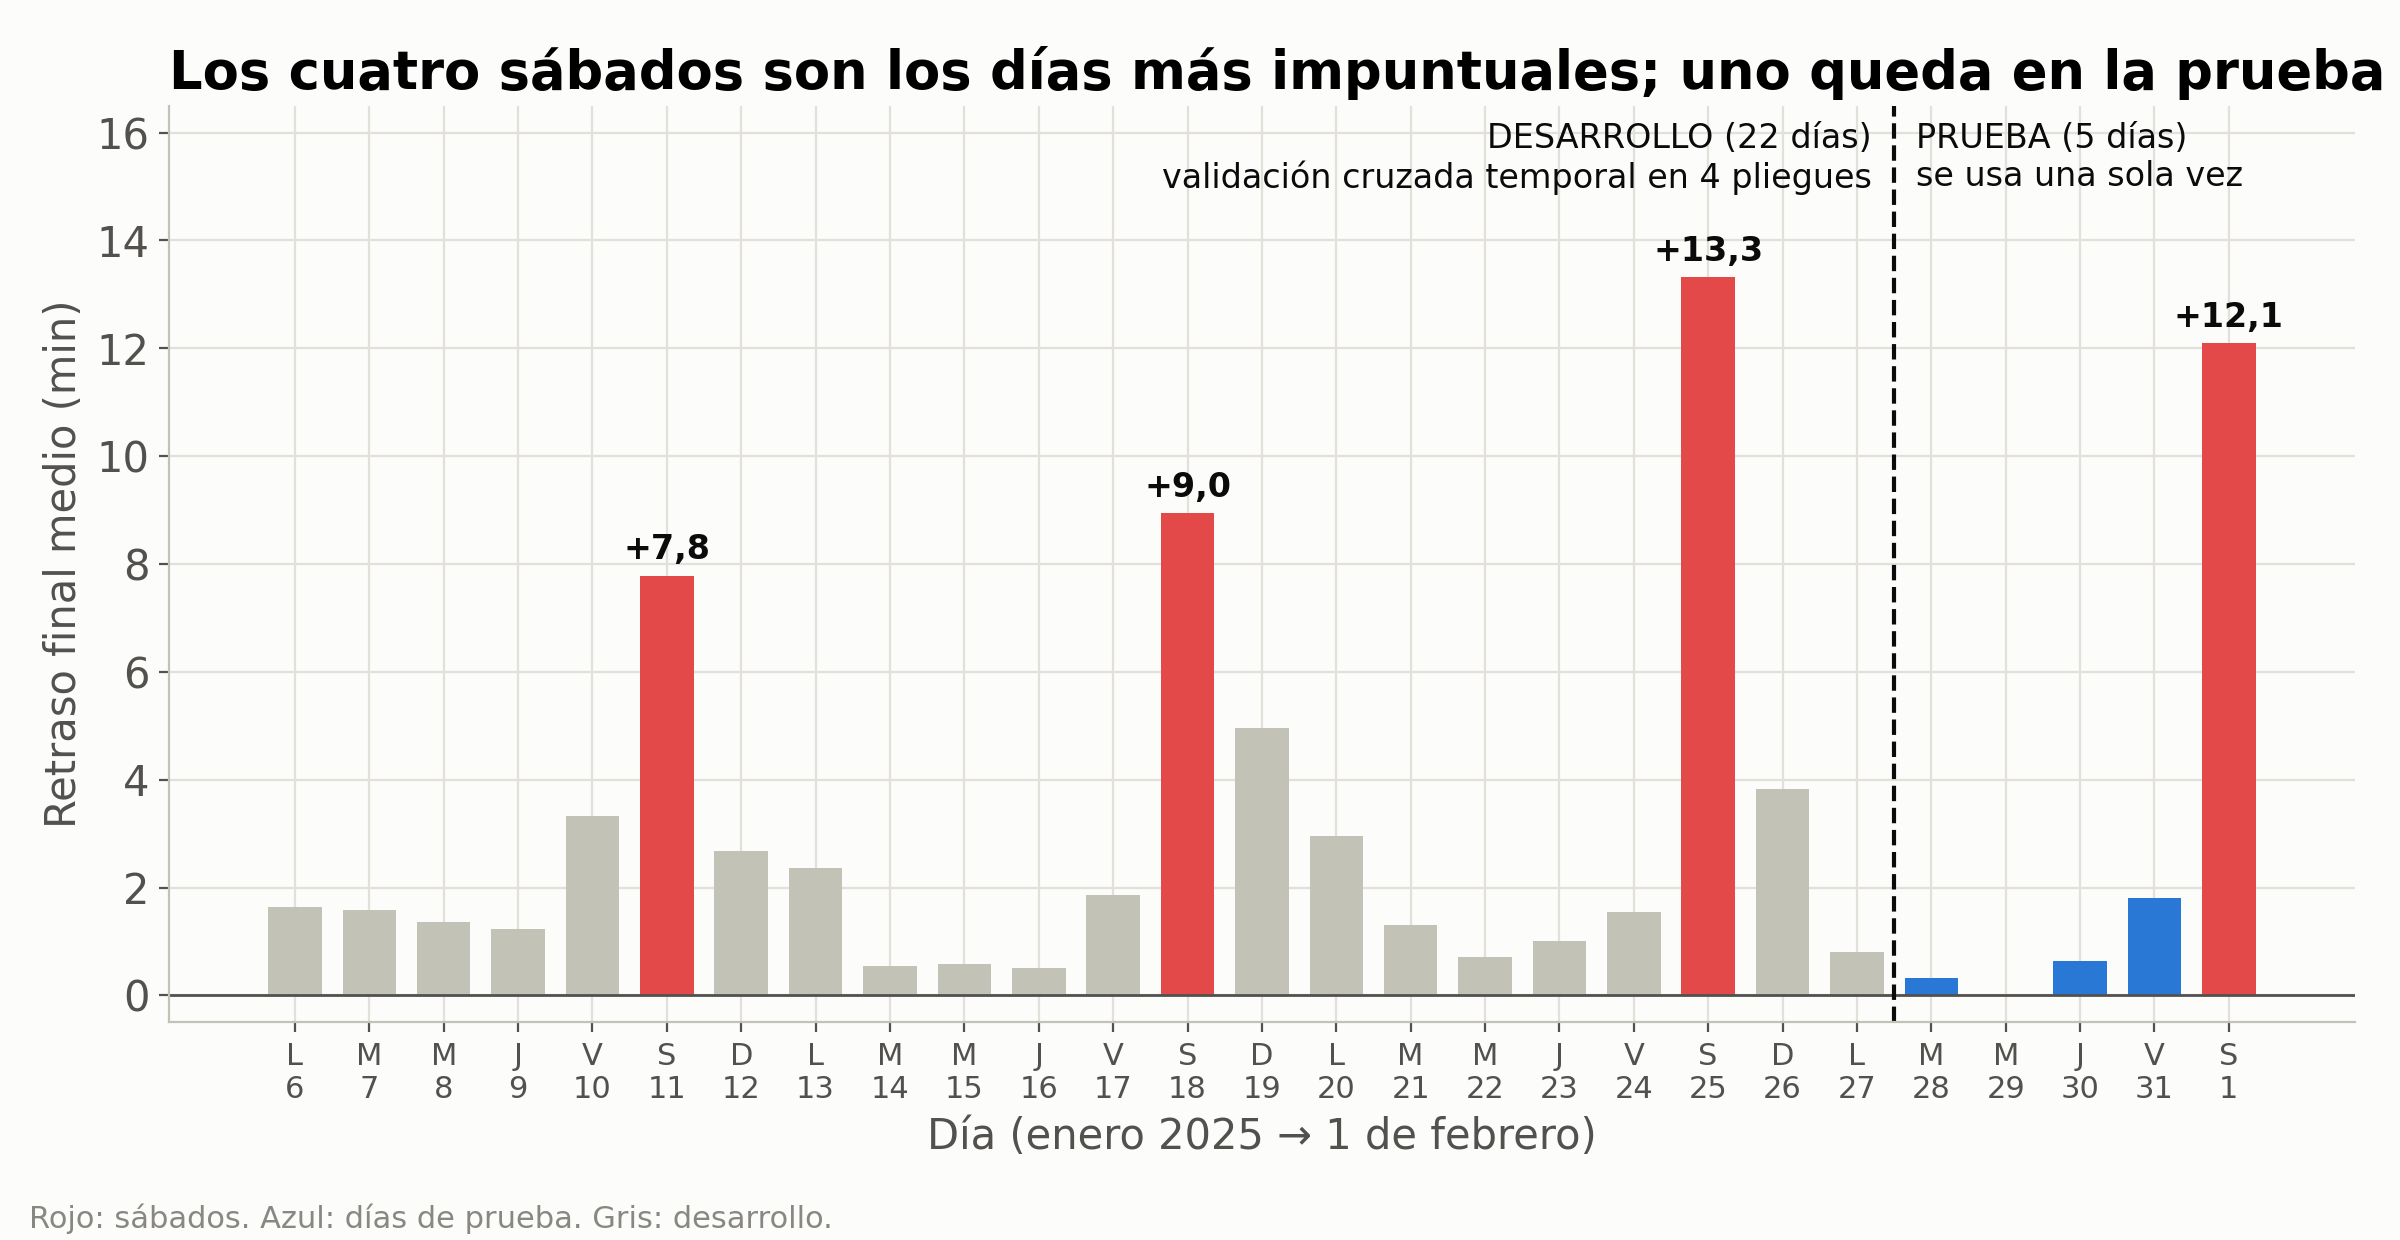

In [6]:
FIG("pres_04_calendario_particion.png")

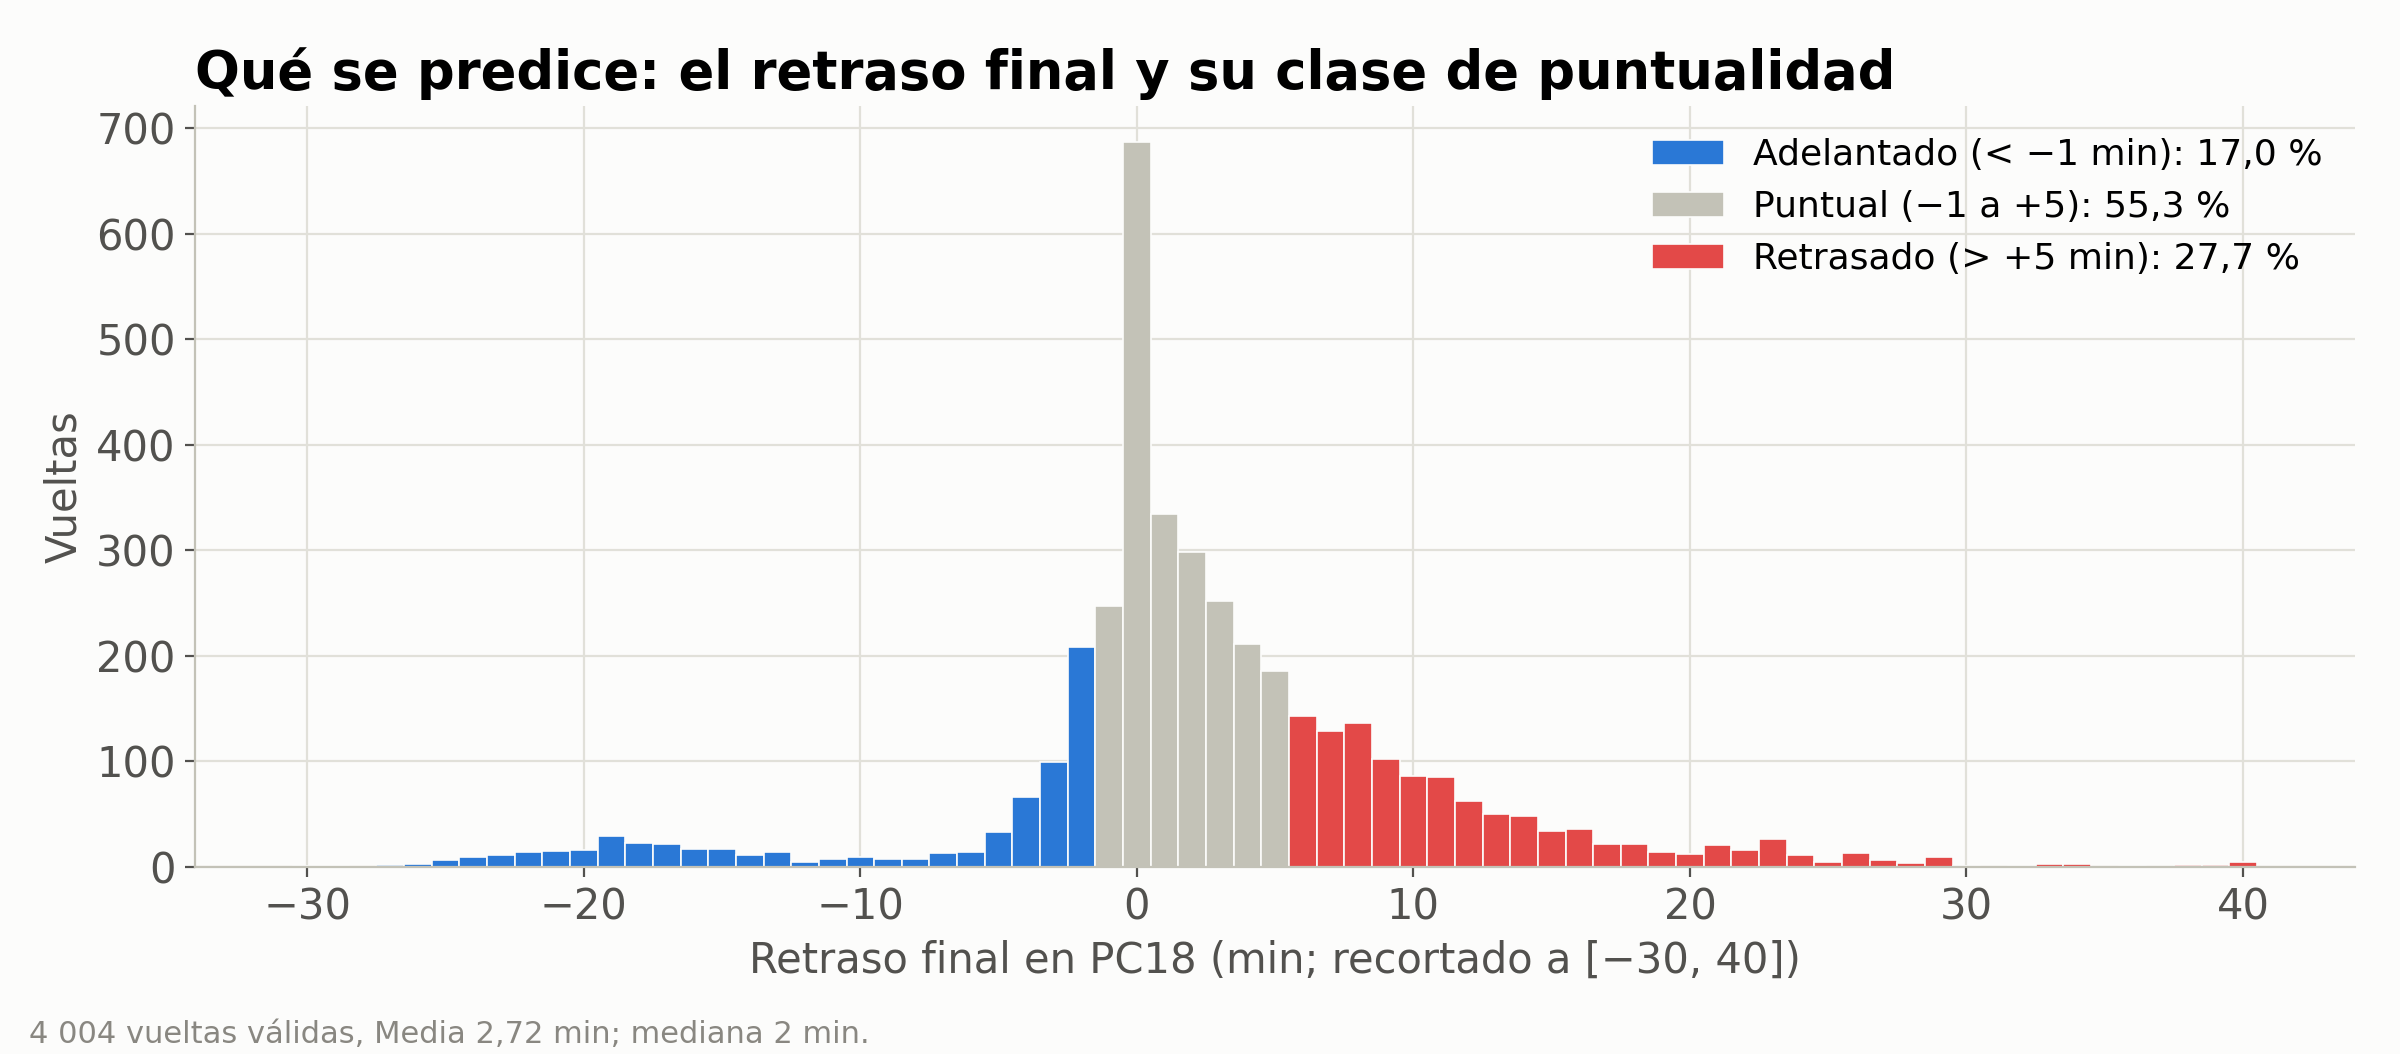

In [7]:
FIG("pres_05_distribucion_clases.png")

## 2. Mejora 1 — variables del día en curso (cribado)

**Hipótesis:** el sábado concentra el 28 % del error; si el modelo supiera "cómo va el día", podría corregirse.

**Regla anti-fuga:** para predecir la vuelta *i* solo se usan vueltas del mismo día cuya **llegada real a PC18 es anterior a la hora
programada de salida** de *i*.

| Grupo | Variables |
|---|---|
| C | retraso medio de las vueltas del día ya terminadas; media de las 5 últimas; n.º de terminadas; retraso de la vuelta anterior del mismo vehículo |
| P | n.º de salidas programadas en los 60 min previos; minutos desde la salida programada anterior (itinerario, conocido de antemano) |
| A | (segundo intento declarado) anomalía del día: retraso de las terminadas **menos** el promedio histórico de su hora, calculado solo con días anteriores |

**Regla de aceptación (D1, fijada antes):** mejorar la media de validación **y** ganar en ≥ 3 de 4 pliegues. XGBoost con los
hiperparámetros elegidos en E2, en k = 0 y k = 12. La prueba no se usa.

In [8]:
cr = R("cribado_CP_-1_5.csv")
cr[["tarea", "k", "grupo", "metrica", "media", "std", "p1", "p2", "p3", "p4", "pliegues_ganados", "dif_media", "acepta_D1"]].round(3)

,tarea,k,grupo,metrica,media,std,p1,p2,p3,p4,pliegues_ganados,dif_media,acepta_D1
0,reg,0,base,MAE,3.150,0.892,3.208,2.763,2.270,4.357,0.0,0.000,False
1,reg,0,+C,MAE,3.206,0.808,3.352,2.949,2.295,4.226,1.0,0.056,False
2,reg,0,+P,MAE,3.178,0.873,3.296,2.797,2.288,4.333,1.0,0.029,False
3,reg,0,+C+P,MAE,3.212,0.784,3.355,2.984,2.315,4.194,1.0,0.063,False
4,reg,0,+A,MAE,3.209,0.894,3.140,2.920,2.328,4.446,1.0,0.059,False
5,reg,12,base,MAE,2.885,0.473,3.091,2.639,2.373,3.438,0.0,0.000,False
6,reg,12,+C,MAE,2.949,0.469,3.051,2.828,2.394,3.521,1.0,0.063,False
7,reg,12,+P,MAE,2.910,0.491,3.177,2.666,2.353,3.442,1.0,0.024,False
8,reg,12,+C+P,MAE,2.949,0.462,3.067,2.839,2.391,3.499,1.0,0.064,False
9,reg,12,+A,MAE,2.848,0.377,2.948,2.801,2.366,3.275,3.0,-0.037,True


**Decisión:** C, P y C+P empeoran la validación en los 4 casos. A pasa la regla solo en regresión con k = 12 (−0,037 min) y empeora
en los otros 3 casos; esa mejora está en el orden del ruido de plataforma (ver sección 3), y adoptarla solo donde funcionó sería
elegir a posteriori. **Ninguna variable del día se incorpora.** Explicación: con 10 a 19 días de entrenamiento por pliegue,
el modelo ve muy pocos "estados del día" distintos para aprender de ellos; es trabajo futuro con más meses de datos.

## 3. Mejora 2 — malla ampliada de XGBoost y umbrales de clase

* **Malla ampliada (D5):** en E2 XGBoost eligió profundidad 3 y tasa 0,03, en el borde de la malla. Se agregan profundidad 2,
  tasa 0,01 y 1 600 árboles (la malla original queda contenida). Random Forest y los lineales mantienen su malla.
* **Umbrales (D4):** se mantienen −1/+5 min (Cao et al.; el rango "1 min antes – 5 min después" es el más usado en la práctica).
  Como análisis de sensibilidad se repite la clasificación con −3/+10, reportando siempre la exactitud de la clase mayoritaria.
* **Reproducibilidad:** XGBoost con submuestreo < 1 varía levemente con el número de hilos y la plataforma (hasta 0,03 min por
  pliegue). Por eso toda la búsqueda se rehízo en una sola máquina, con 1 hilo por modelo (resultado determinista).

In [9]:
cv = R("cv_raw.csv")
print("combinaciones evaluadas:", len(cv), "(cada una en 4 pliegues)")
cv.groupby(["tarea", "umbral", "modelo"]).size().unstack()

combinaciones evaluadas: 4165 (cada una en 4 pliegues)


modelo        logistic     rf  ridge     xgb
tarea umbral                                
clf   amplio      70.0  252.0    NaN  1344.0
      cao         70.0  252.0    NaN  1344.0
reg   -            NaN  126.0   35.0   672.0

In [10]:
mej, ori = R("cv_mejores.csv"), R("cv_mejores_malla_original.csv")
x = mej[mej.modelo == "xgb"].merge(ori[ori.modelo == "xgb"], on=["tarea", "umbral", "modelo", "k", "conjunto"], suffixes=("_ampl", "_orig"))
x[["tarea", "umbral", "k", "conjunto", "metrica_media_orig", "metrica_media_ampl", "params_ampl"]].round(4)

,tarea,umbral,k,conjunto,metrica_media_orig,metrica_media_ampl,params_ampl
0,clf,amplio,12,F2,0.7757,0.7757,"{""class_weight"": ""balanced"", ""learning_rate"": ..."
1,clf,amplio,12,F1,0.7610,0.7638,"{""class_weight"": ""balanced"", ""learning_rate"": ..."
2,clf,amplio,8,F1,0.7421,0.7450,"{""class_weight"": ""balanced"", ""learning_rate"": ..."
3,clf,amplio,8,F2,0.7366,0.7366,"{""class_weight"": ""balanced"", ""learning_rate"": ..."
4,clf,amplio,4,F2,0.7329,0.7345,"{""class_weight"": ""balanced"", ""learning_rate"": ..."
5,clf,cao,12,F1,0.7302,0.7338,"{""class_weight"": null, ""learning_rate"": 0.1, ""..."
6,clf,amplio,4,F1,0.7311,0.7311,"{""class_weight"": ""balanced"", ""learning_rate"": ..."
7,clf,amplio,0,F0,0.7303,0.7303,"{""class_weight"": ""balanced"", ""learning_rate"": ..."
8,clf,cao,12,F2,0.7283,0.7283,"{""class_weight"": null, ""learning_rate"": 0.03, ..."
9,clf,cao,8,F2,0.7189,0.7239,"{""class_weight"": null, ""learning_rate"": 0.01, ..."


## 4. Validación cruzada (selección de modelos)

In [11]:
base = R("cv_lineas_base.csv")
def tabla_cv(tarea, umbral):
    t = mej[(mej.tarea == tarea) & (mej.umbral == umbral)].copy()
    t["esc"] = "k=" + t.k.astype(str) + " " + t.conjunto
    t["v"] = t.metrica_media.map("{:.3f}".format) + " ± " + t.metrica_std.map("{:.3f}".format)
    return t.pivot(index="modelo", columns="esc", values="v")[["k=0 F0", "k=4 F1", "k=8 F1", "k=12 F1", "k=4 F2", "k=8 F2", "k=12 F2"]]
display(Markdown("**MAE de validación (min)**")); display(tabla_cv("reg", "-"))
display(Markdown("**F1-macro de validación (−1/+5)**")); display(tabla_cv("clf", "cao"))
display(Markdown("**Líneas base en validación**")); display(base.round(3))

**MAE de validación (min)**

esc,k=0 F0,k=4 F1,k=8 F1,k=12 F1,k=4 F2,k=8 F2,k=12 F2
modelo,,,,,,,
rf,3.271 ± 0.856,3.255 ± 0.839,3.176 ± 0.739,3.010 ± 0.542,3.239 ± 0.813,3.193 ± 0.768,3.024 ± 0.543
ridge,4.104 ± 0.735,3.946 ± 0.705,3.613 ± 0.628,3.081 ± 0.296,3.954 ± 0.715,3.618 ± 0.631,3.072 ± 0.293
xgb,3.116 ± 0.885,3.139 ± 0.840,3.112 ± 0.806,2.867 ± 0.454,3.166 ± 0.822,3.103 ± 0.805,2.873 ± 0.456


**F1-macro de validación (−1/+5)**

esc,k=0 F0,k=4 F1,k=8 F1,k=12 F1,k=4 F2,k=8 F2,k=12 F2
modelo,,,,,,,
logistic,0.654 ± 0.075,0.674 ± 0.051,0.695 ± 0.054,0.713 ± 0.070,0.671 ± 0.053,0.694 ± 0.055,0.715 ± 0.066
rf,0.709 ± 0.044,0.711 ± 0.042,0.714 ± 0.050,0.721 ± 0.060,0.703 ± 0.057,0.703 ± 0.054,0.715 ± 0.050
xgb,0.714 ± 0.036,0.708 ± 0.052,0.724 ± 0.063,0.734 ± 0.060,0.708 ± 0.059,0.724 ± 0.057,0.728 ± 0.048


**Líneas base en validación**

,tarea,umbral,modelo,k,mean,std
0,clf,amplio,B1 persistencia,4,0.347,0.045
1,clf,amplio,B1 persistencia,8,0.625,0.040
2,clf,amplio,B1 persistencia,12,0.642,0.064
3,clf,amplio,B2 histórico,0,0.286,0.022
4,clf,amplio,B2 histórico,4,0.286,0.022
5,clf,amplio,B2 histórico,8,0.286,0.022
6,clf,amplio,B2 histórico,12,0.286,0.022
7,clf,cao,B1 persistencia,4,0.403,0.033
8,clf,cao,B1 persistencia,8,0.557,0.082
9,clf,cao,B1 persistencia,12,0.562,0.120


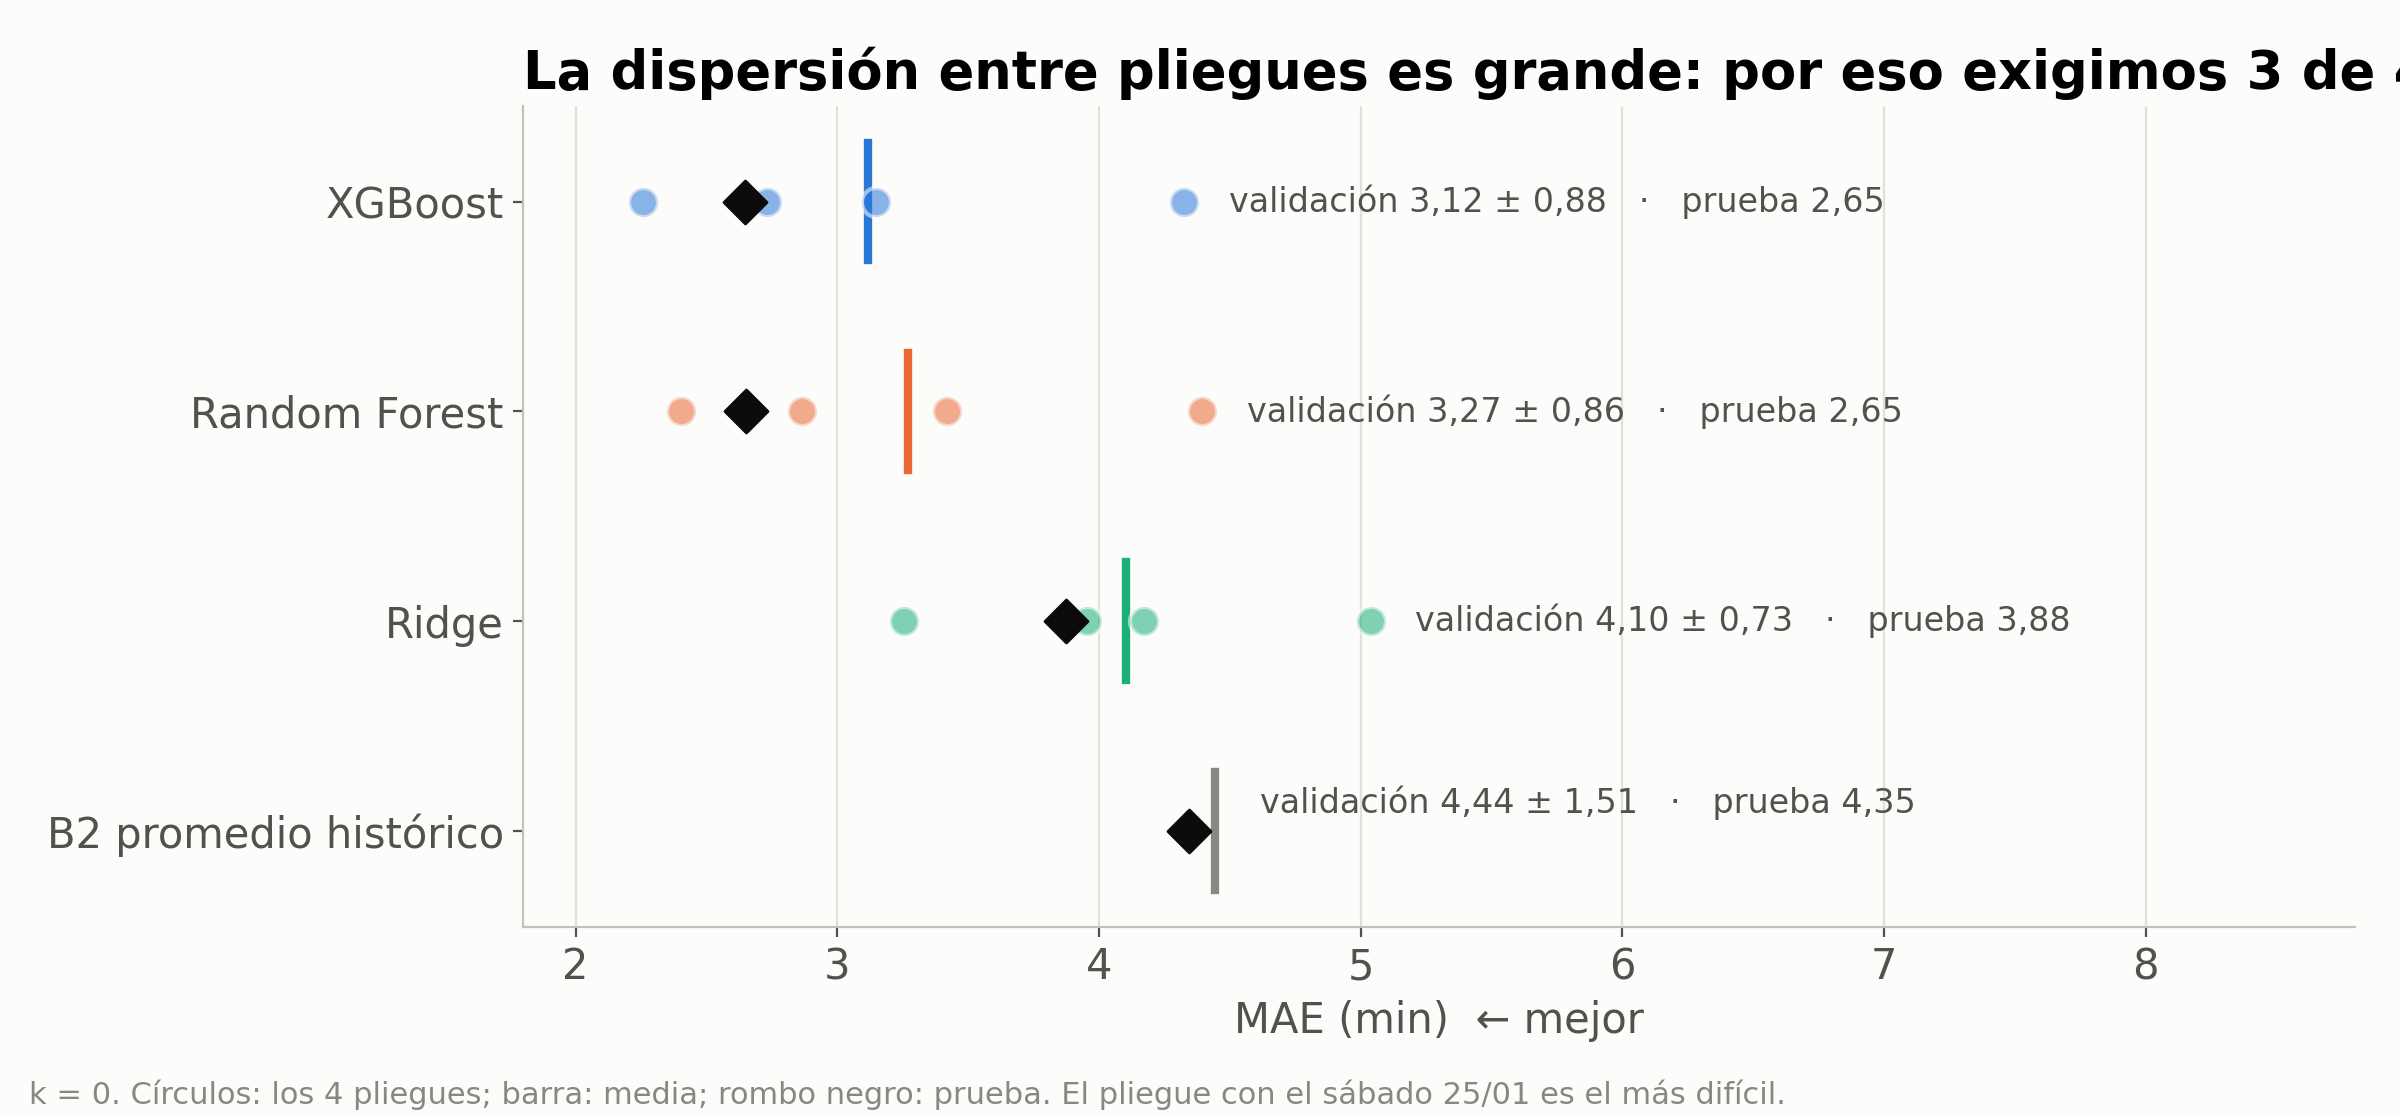

In [12]:
FIG("pres_11_pliegues_validacion.png")

## 5. Evaluación única en el conjunto de prueba

In [13]:
res = R("test_resultados.csv")
def tabla(tarea, umbral, met):
    t = res[(res.tarea == tarea) & (res.umbral == umbral)].copy(); t["esc"] = "k=" + t.k.astype(str) + " " + t.conjunto
    return t.pivot(index="modelo", columns="esc", values=met)[["k=0 F0", "k=4 F1", "k=8 F1", "k=12 F1", "k=4 F2", "k=8 F2", "k=12 F2"]].round(3)
for met in ("MAE", "RMSE", "R2"):
    display(Markdown(f"**{met} en prueba**")); display(tabla("reg", "-", met))
for met in ("F1_macro", "exactitud", "exactitud_bal", "kappa", "recall_retrasado", "PR_AUC"):
    display(Markdown(f"**{met} en prueba (−1/+5)**")); display(tabla("clf", "cao", met))

**MAE en prueba**

esc,k=0 F0,k=4 F1,k=8 F1,k=12 F1,k=4 F2,k=8 F2,k=12 F2
modelo,,,,,,,
B1 persistencia,NaN,5.264,3.982,3.670,5.264,3.982,3.670
B2 histórico,4.346,4.346,4.346,4.346,4.346,4.346,4.346
rf,2.650,2.658,2.726,2.494,2.725,2.766,2.546
ridge,3.876,3.770,3.472,2.795,3.773,3.463,2.800
xgb,2.649,2.649,2.642,2.374,2.675,2.694,2.354


**RMSE en prueba**

esc,k=0 F0,k=4 F1,k=8 F1,k=12 F1,k=4 F2,k=8 F2,k=12 F2
modelo,,,,,,,
B1 persistencia,NaN,8.228,5.967,5.336,8.228,5.967,5.336
B2 histórico,6.227,6.227,6.227,6.227,6.227,6.227,6.227
rf,4.126,4.124,4.198,3.805,4.198,4.225,3.820
ridge,5.330,5.210,4.814,3.956,5.225,4.793,3.947
xgb,4.113,4.078,4.052,3.606,4.096,4.145,3.566


**R2 en prueba**

esc,k=0 F0,k=4 F1,k=8 F1,k=12 F1,k=4 F2,k=8 F2,k=12 F2
modelo,,,,,,,
B1 persistencia,NaN,-0.001,0.473,0.579,-0.001,0.473,0.579
B2 histórico,0.426,0.426,0.426,0.426,0.426,0.426,0.426
rf,0.748,0.748,0.739,0.786,0.739,0.736,0.784
ridge,0.580,0.598,0.657,0.769,0.596,0.660,0.770
xgb,0.750,0.754,0.757,0.808,0.752,0.746,0.812


... (8 outputs left out)

**recall_retrasado en prueba (−1/+5)**

esc,k=0 F0,k=4 F1,k=8 F1,k=12 F1,k=4 F2,k=8 F2,k=12 F2
modelo,,,,,,,
B1 persistencia,NaN,0.000,0.299,0.466,0.000,0.299,0.466
B2 histórico,0.000,0.000,0.000,0.000,0.000,0.000,0.000
logistic,0.494,0.517,0.529,0.557,0.511,0.523,0.552
rf,0.822,0.862,0.759,0.879,0.782,0.776,0.856
xgb,0.770,0.805,0.787,0.828,0.810,0.816,0.816


**PR_AUC en prueba (−1/+5)**

esc,k=0 F0,k=4 F1,k=8 F1,k=12 F1,k=4 F2,k=8 F2,k=12 F2
modelo,,,,,,,
B1 persistencia,NaN,0.401,0.504,0.548,0.401,0.504,0.548
B2 histórico,0.333,0.333,0.333,0.333,0.333,0.333,0.333
logistic,0.739,0.761,0.773,0.796,0.755,0.772,0.794
rf,0.809,0.805,0.793,0.811,0.779,0.789,0.807
xgb,0.818,0.818,0.812,0.826,0.806,0.804,0.819


In [14]:
display(Markdown("**Sensibilidad y especificidad por clase (XGBoost, prueba, −1/+5)**"))
c = res[(res.tarea == "clf") & (res.umbral == "cao") & (res.modelo == "xgb")]
c[["k", "conjunto", "exactitud", "exactitud_bal", "kappa", "sens_adel", "espec_adel", "sens_punt", "espec_punt", "sens_retr", "espec_retr"]].round(3)

**Sensibilidad y especificidad por clase (XGBoost, prueba, −1/+5)**

,k,conjunto,exactitud,exactitud_bal,kappa,sens_adel,espec_adel,sens_punt,espec_punt,sens_retr,espec_retr
10,12,F1,0.790,0.736,0.617,0.526,0.976,0.855,0.699,0.828,0.913
15,12,F2,0.792,0.735,0.618,0.526,0.971,0.862,0.693,0.816,0.923
17,8,F2,0.778,0.720,0.594,0.496,0.981,0.849,0.680,0.816,0.902
18,8,F1,0.770,0.715,0.580,0.519,0.979,0.840,0.670,0.787,0.899
24,0,F0,0.780,0.722,0.595,0.541,0.968,0.855,0.670,0.770,0.923
29,4,F1,0.785,0.732,0.607,0.541,0.976,0.851,0.689,0.805,0.911
30,4,F2,0.778,0.726,0.597,0.526,0.970,0.842,0.689,0.810,0.909


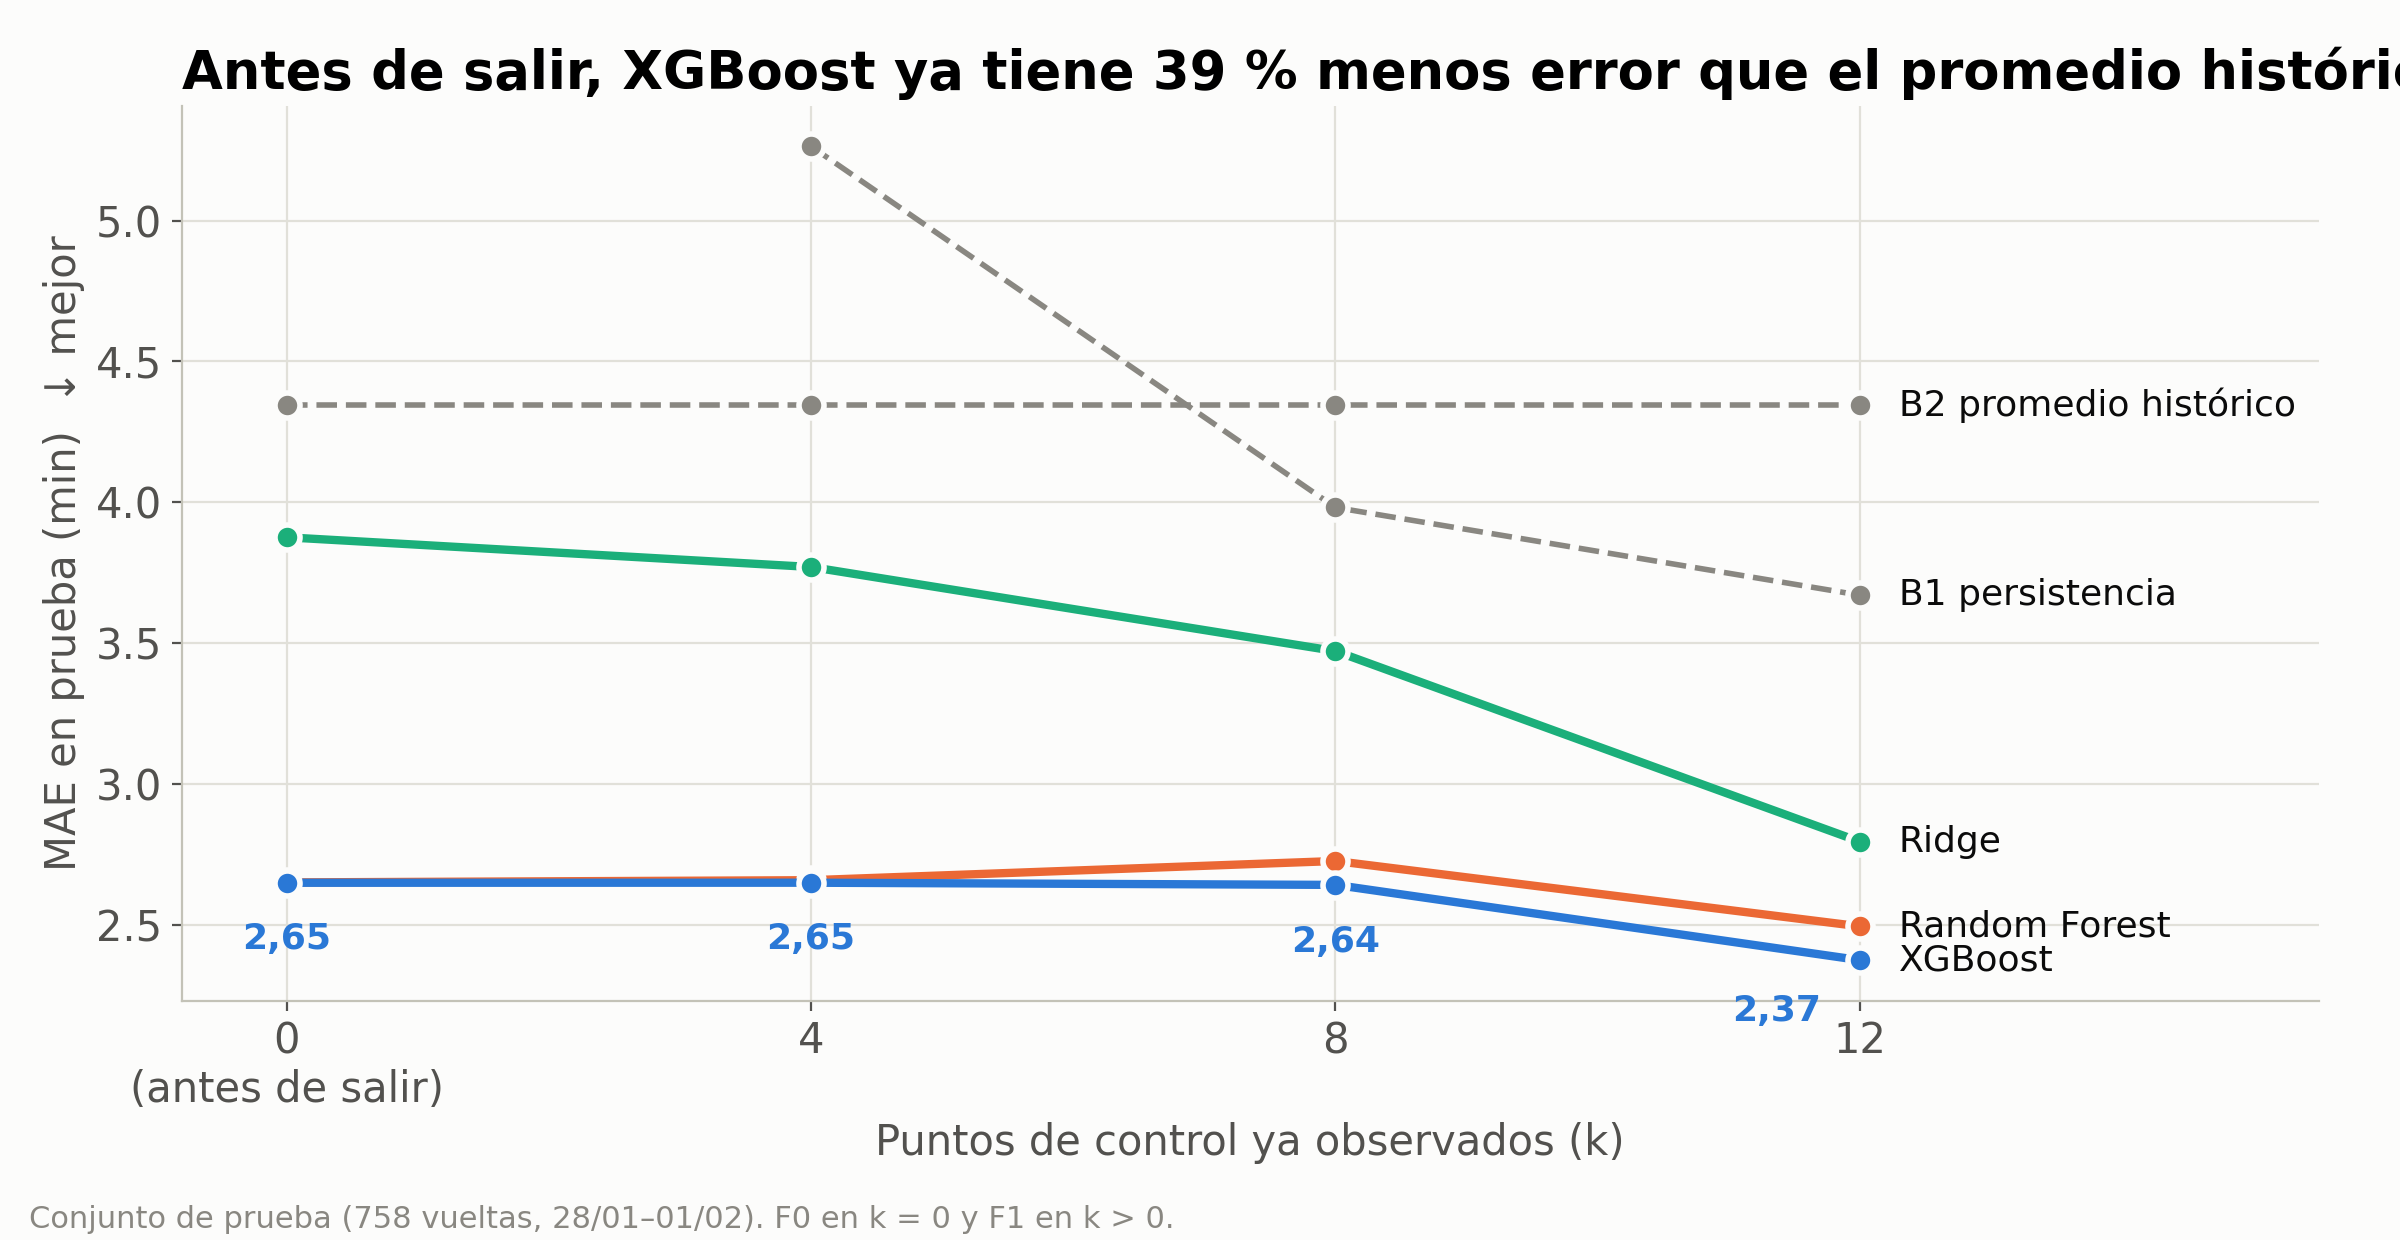

In [15]:
FIG("pres_10_mae_vs_k.png")

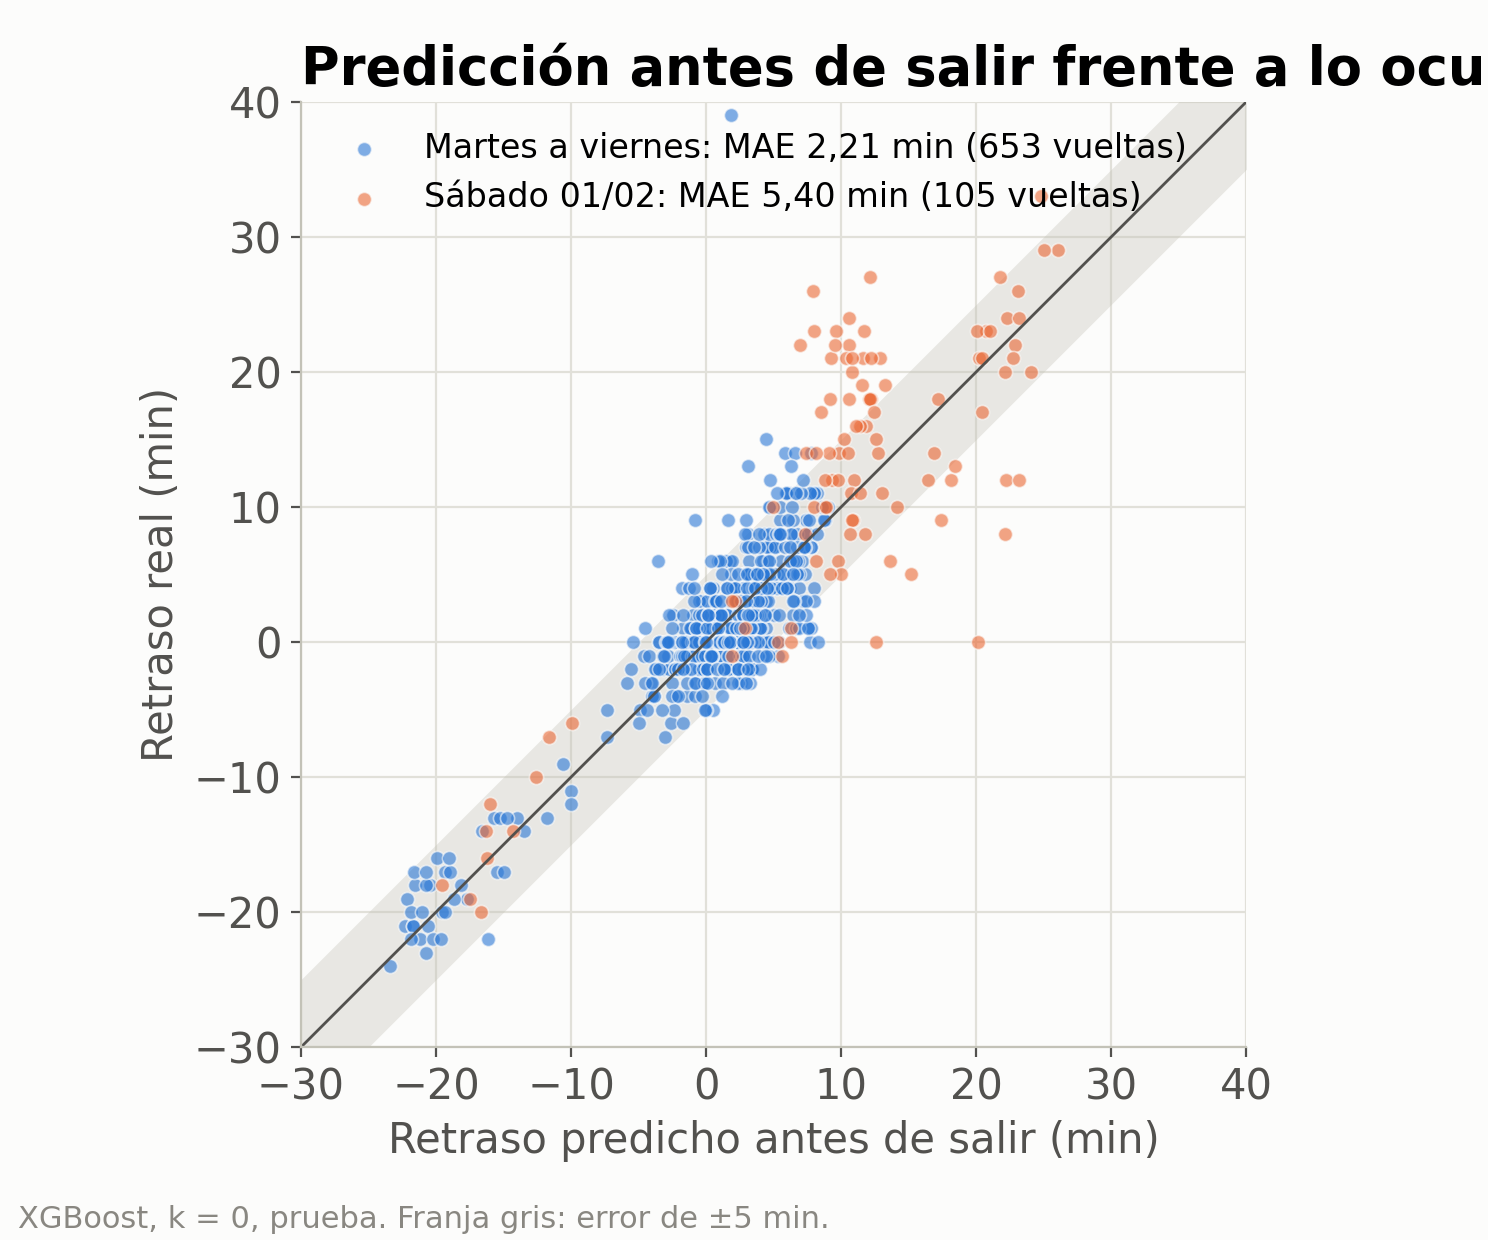

In [16]:
FIG("pres_12_predicho_vs_real.png")

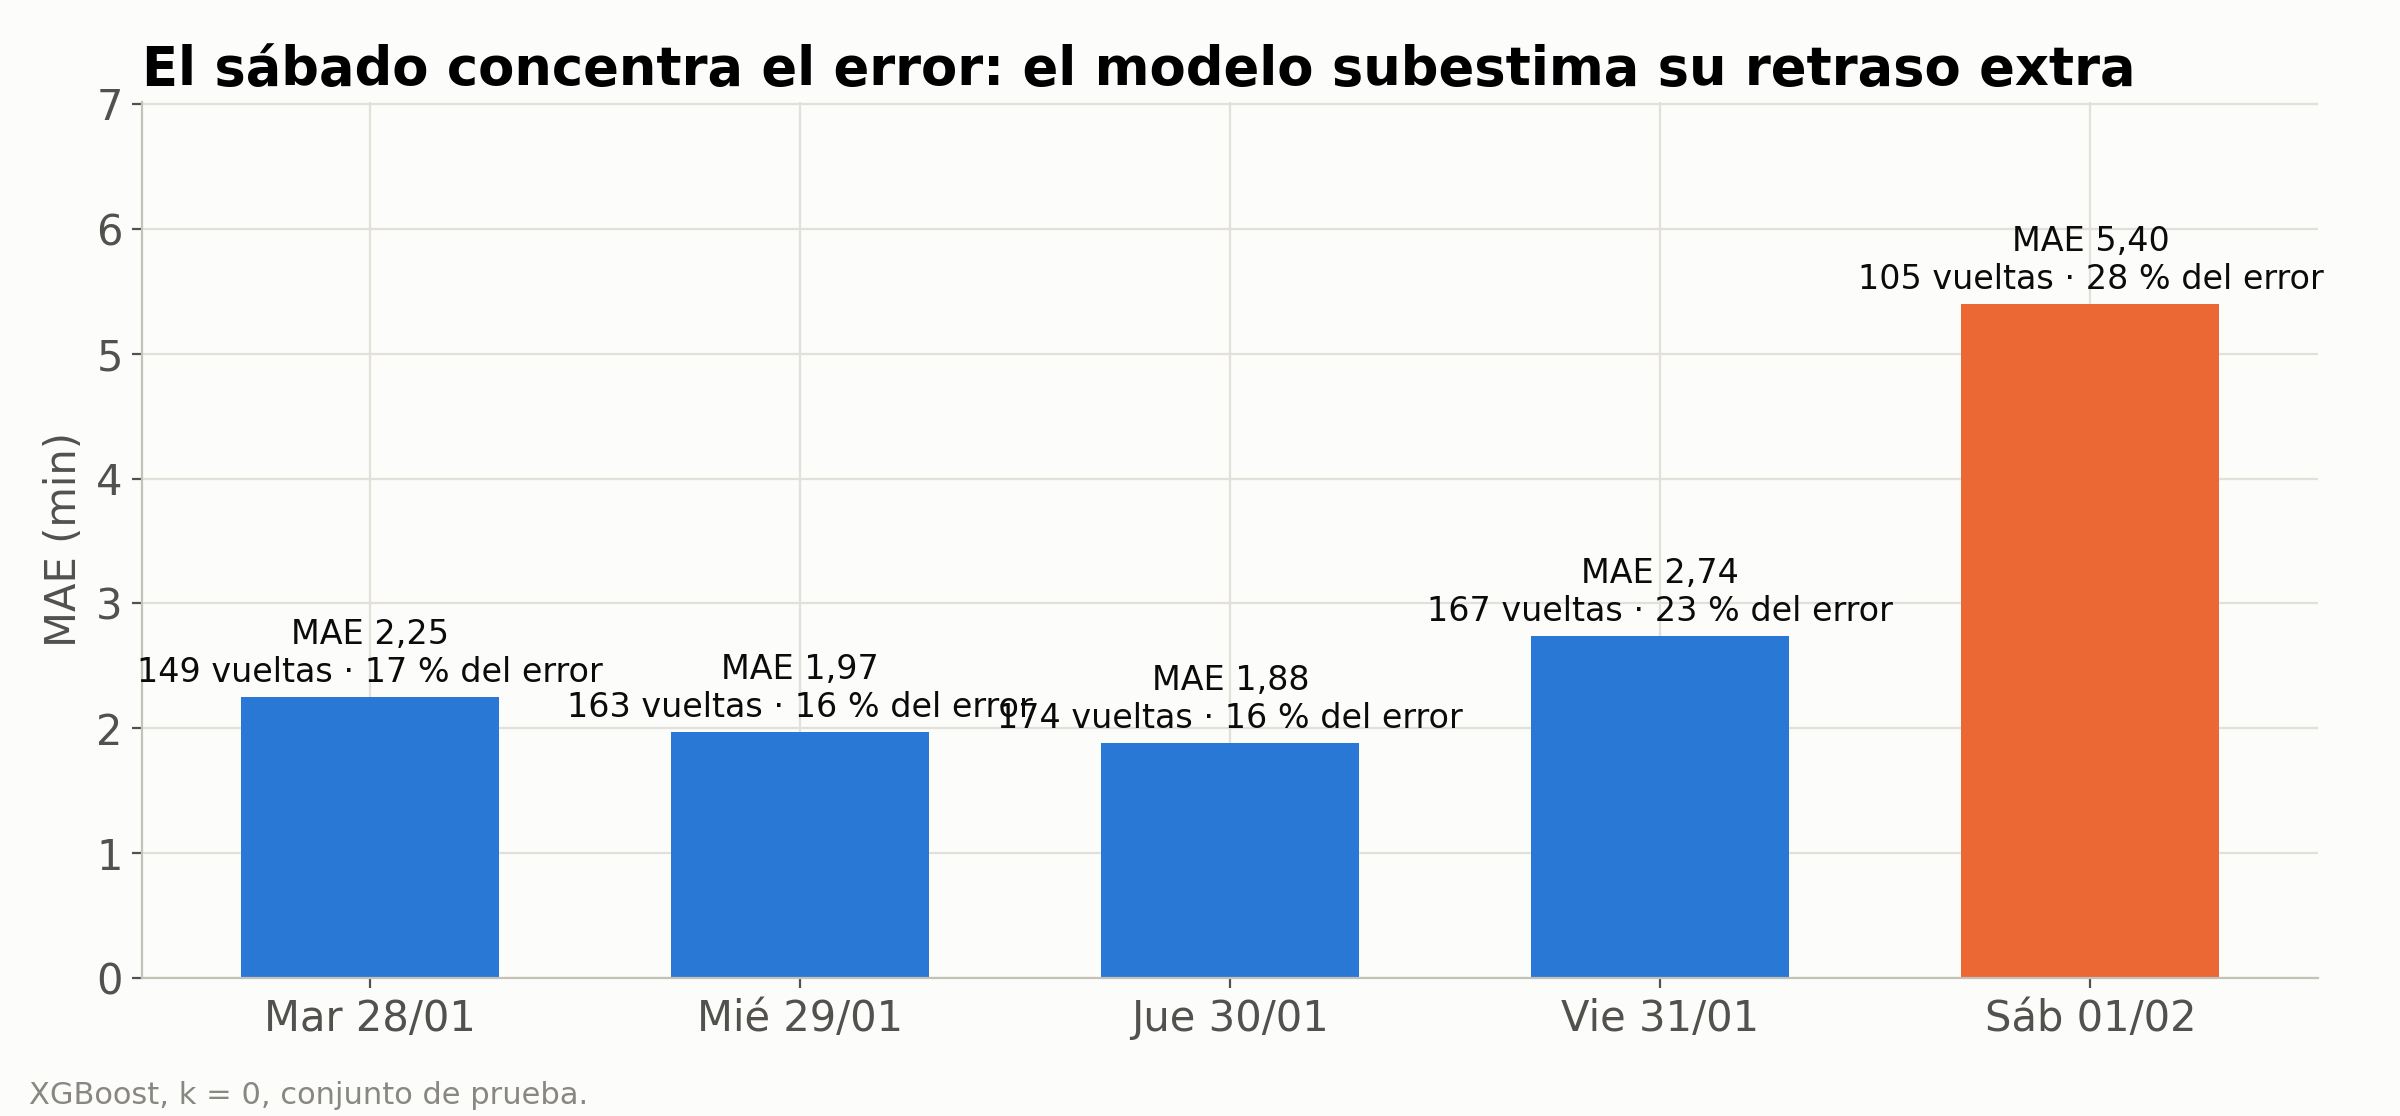

In [17]:
FIG("pres_13_error_por_dia.png")

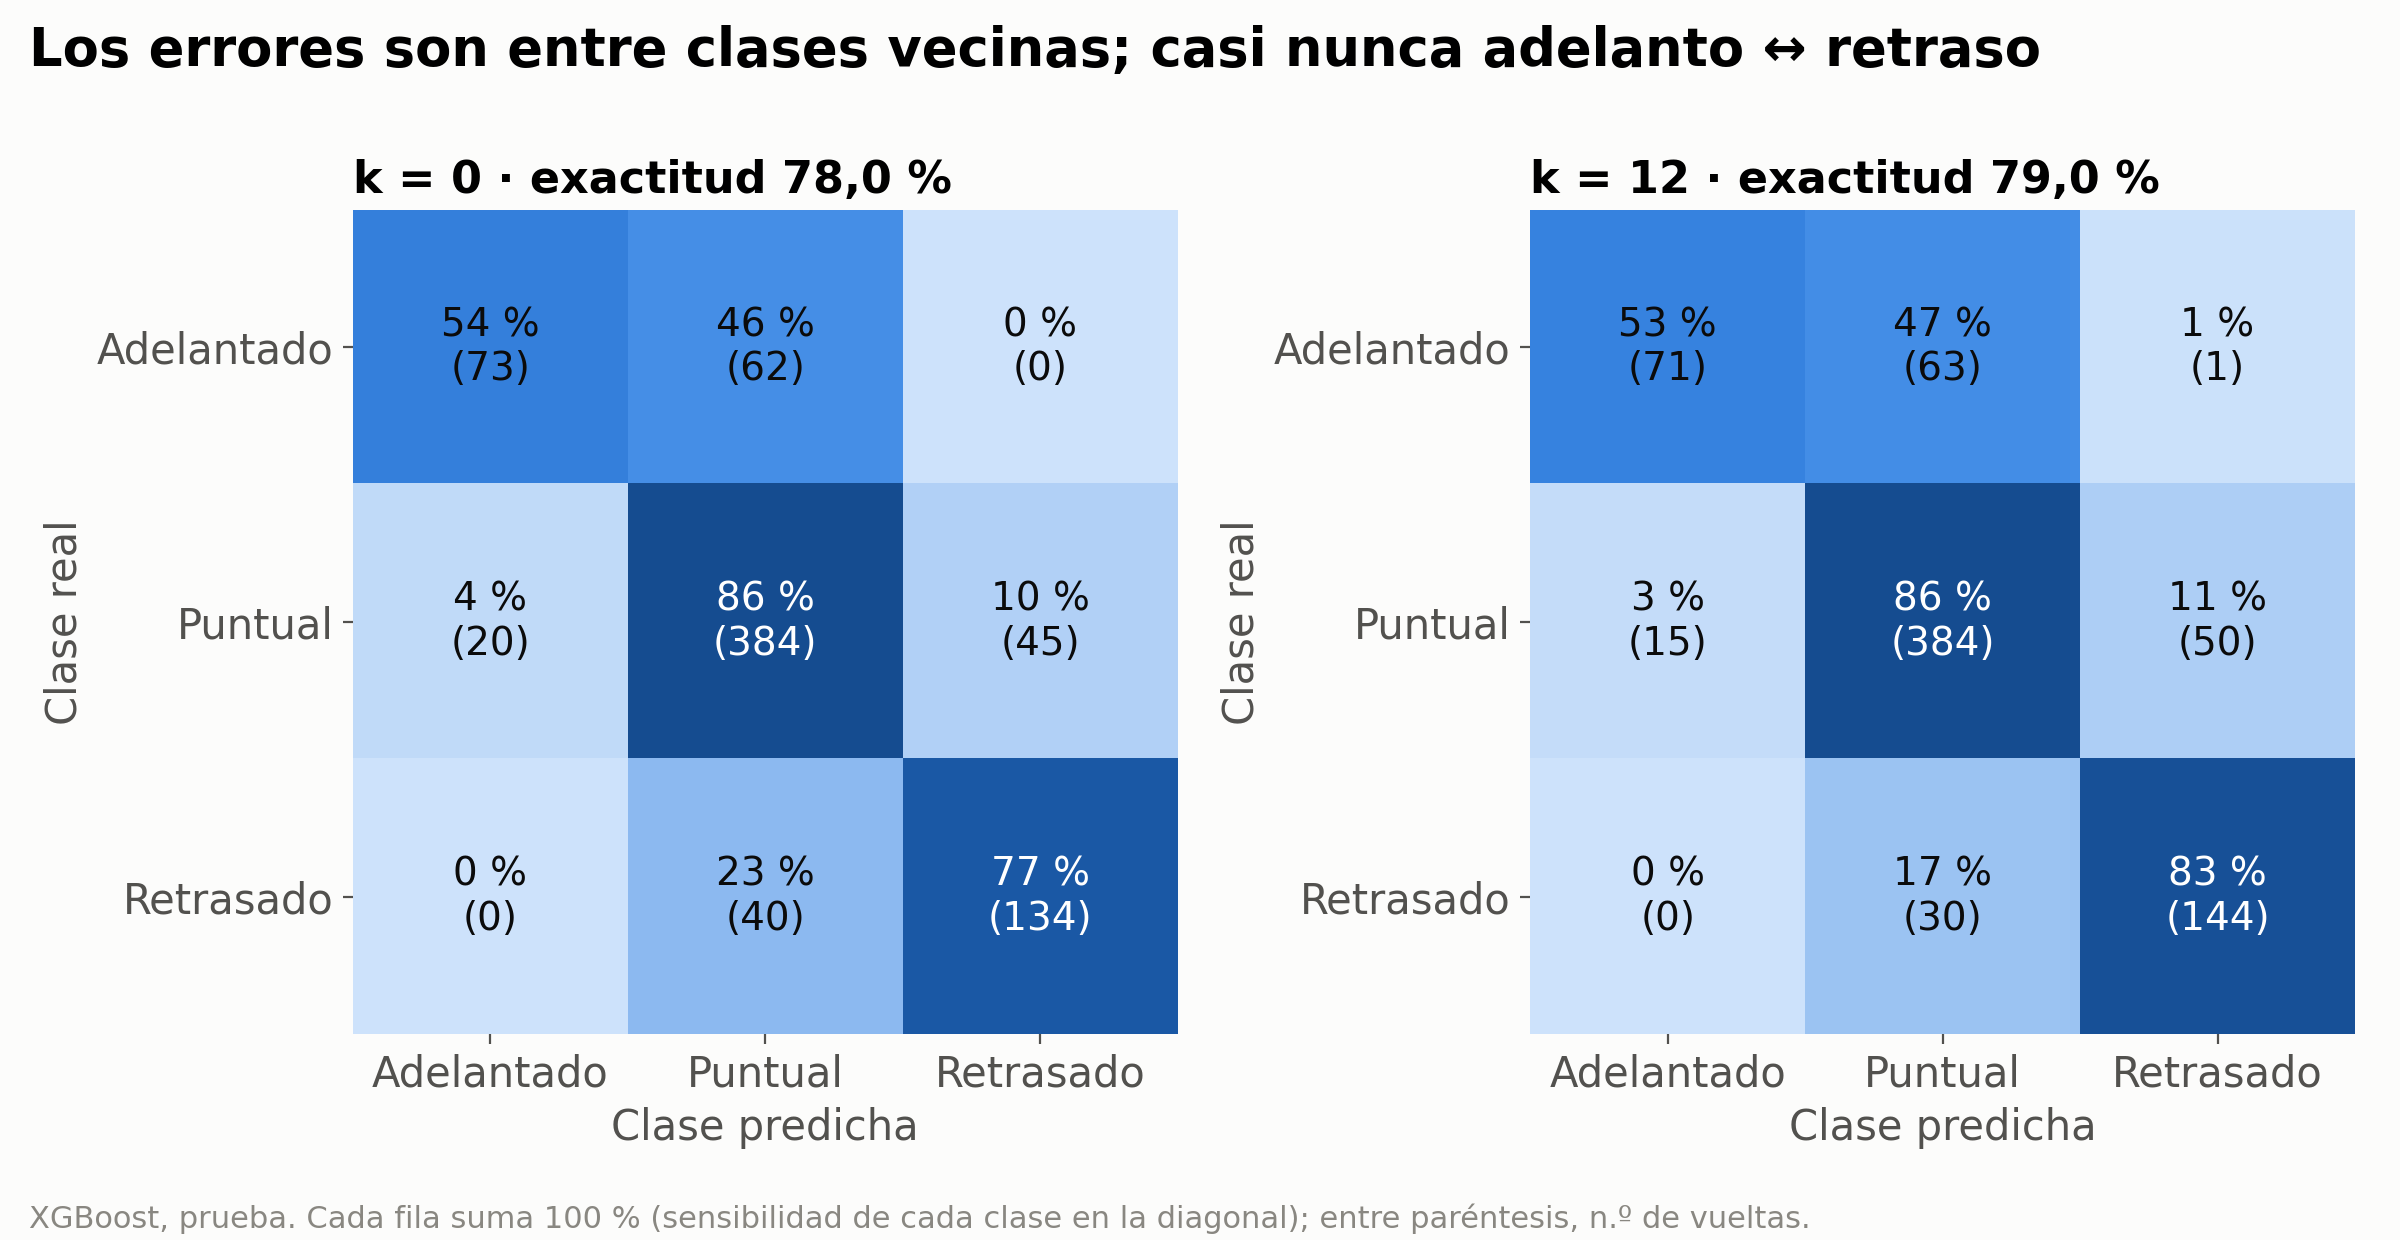

In [18]:
FIG("pres_14_confusion.png")

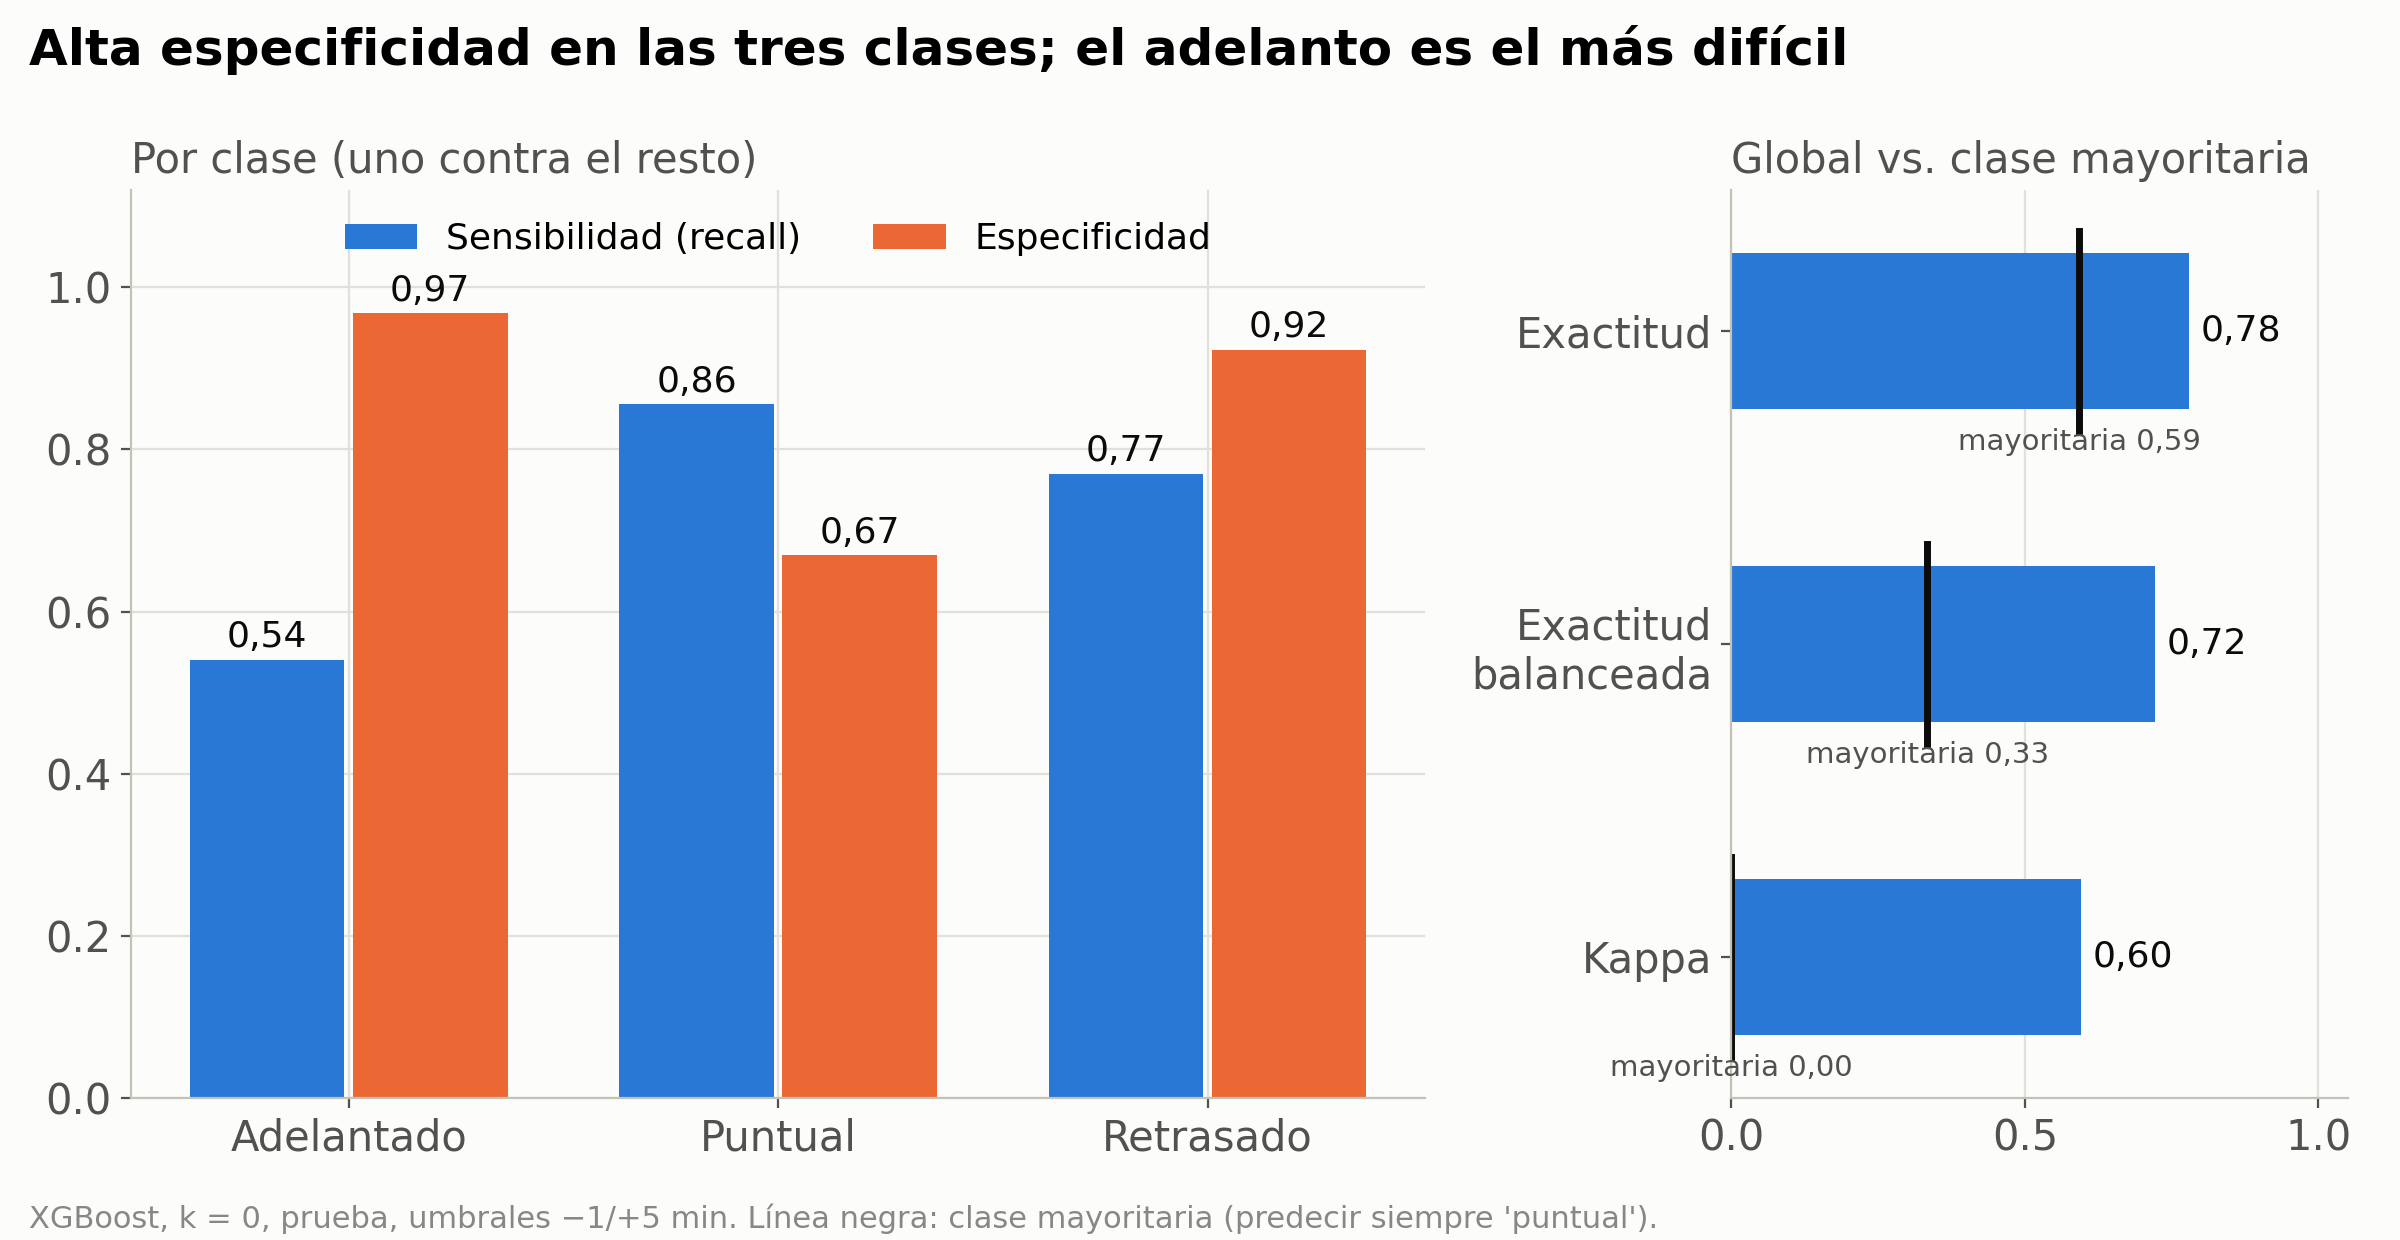

In [19]:
FIG("pres_15_sens_espec.png")

## 6. Pruebas de hipótesis (Wilcoxon / McNemar, α = 0,05)

In [20]:
for f, t in (("test_h1.csv", "H1: mejor modelo vs líneas base"), ("test_h2.csv", "H2: efecto de k"), ("test_h3.csv", "H3: F1 vs F2 (GPS)"),
             ("test_xgb_vs_rf.csv", "D6: XGBoost vs Random Forest (Holm por 7 escenarios)")):
    display(Markdown(f"**{t}**")); display(R(f).round(4))

**H1: mejor modelo vs líneas base**

,tarea,umbral,k,conjunto,mejor,valor_mejor,base,valor_base,p
0,reg,-,0,F0,xgb,2.6491,B2 histórico,4.3455,0.0000
1,reg,-,4,F1,xgb,2.6492,B1 persistencia,5.2639,0.0000
2,reg,-,4,F1,xgb,2.6492,B2 histórico,4.3455,0.0000
3,reg,-,8,F1,xgb,2.6415,B1 persistencia,3.9815,0.0000
4,reg,-,8,F1,xgb,2.6415,B2 histórico,4.3455,0.0000
5,reg,-,12,F1,xgb,2.3743,B1 persistencia,3.6702,0.0000
6,reg,-,12,F1,xgb,2.3743,B2 histórico,4.3455,0.0000
7,reg,-,4,F2,xgb,2.6750,B1 persistencia,5.2639,0.0000
8,reg,-,4,F2,xgb,2.6750,B2 histórico,4.3455,0.0000
9,reg,-,8,F2,xgb,2.6938,B1 persistencia,3.9815,0.0000


**H2: efecto de k**

,tarea,modelo,de,a,valor_de,valor_a,p
0,reg,ridge,0,4,3.8757,3.7703,0.0510
1,reg,ridge,4,8,3.7703,3.4716,0.0000
2,reg,ridge,8,12,3.4716,2.7950,0.0000
3,reg,ridge,0,12,3.8757,2.7950,0.0000
4,reg,rf,0,4,2.6503,2.6582,0.9327
5,reg,rf,4,8,2.6582,2.7263,0.2347
6,reg,rf,8,12,2.7263,2.4943,0.0021
7,reg,rf,0,12,2.6503,2.4943,0.2722
8,reg,xgb,0,4,2.6491,2.6492,0.9830
9,reg,xgb,4,8,2.6492,2.6415,0.5056


**H3: F1 vs F2 (GPS)**

,tarea,modelo,k,valor_F1,valor_F2,p
0,reg,ridge,4,3.7703,3.7729,0.9215
1,reg,ridge,8,3.4716,3.4632,0.8721
2,reg,ridge,12,2.7950,2.8002,0.2699
3,reg,rf,4,2.6582,2.7248,0.0764
4,reg,rf,8,2.7263,2.7660,0.1191
5,reg,rf,12,2.4943,2.5462,0.1085
6,reg,xgb,4,2.6492,2.6750,0.2860
7,reg,xgb,8,2.6415,2.6938,0.1220
8,reg,xgb,12,2.3743,2.3542,0.9254
9,clf,logistic,4,0.7079,0.6959,0.1094


**D6: XGBoost vs Random Forest (Holm por 7 escenarios)**

,tarea,k,conjunto,XGB,RF,p,p_holm,significativo_holm
0,reg,0,F0,2.6491,2.6503,0.7422,1.0000,False
1,reg,4,F1,2.6492,2.6582,0.8560,1.0000,False
2,reg,8,F1,2.6415,2.7263,0.0458,0.1833,False
3,reg,12,F1,2.3743,2.4943,0.0011,0.0068,True
4,reg,4,F2,2.6750,2.7248,0.2286,0.6858,False
5,reg,8,F2,2.6938,2.7660,0.0215,0.1076,False
6,reg,12,F2,2.3542,2.5462,0.0000,0.0003,True
7,clf,0,F0,0.7403,0.7328,0.8875,1.0000,False
8,clf,4,F1,0.7480,0.7218,0.0010,0.0073,True
9,clf,8,F1,0.7317,0.7288,1.0000,1.0000,False


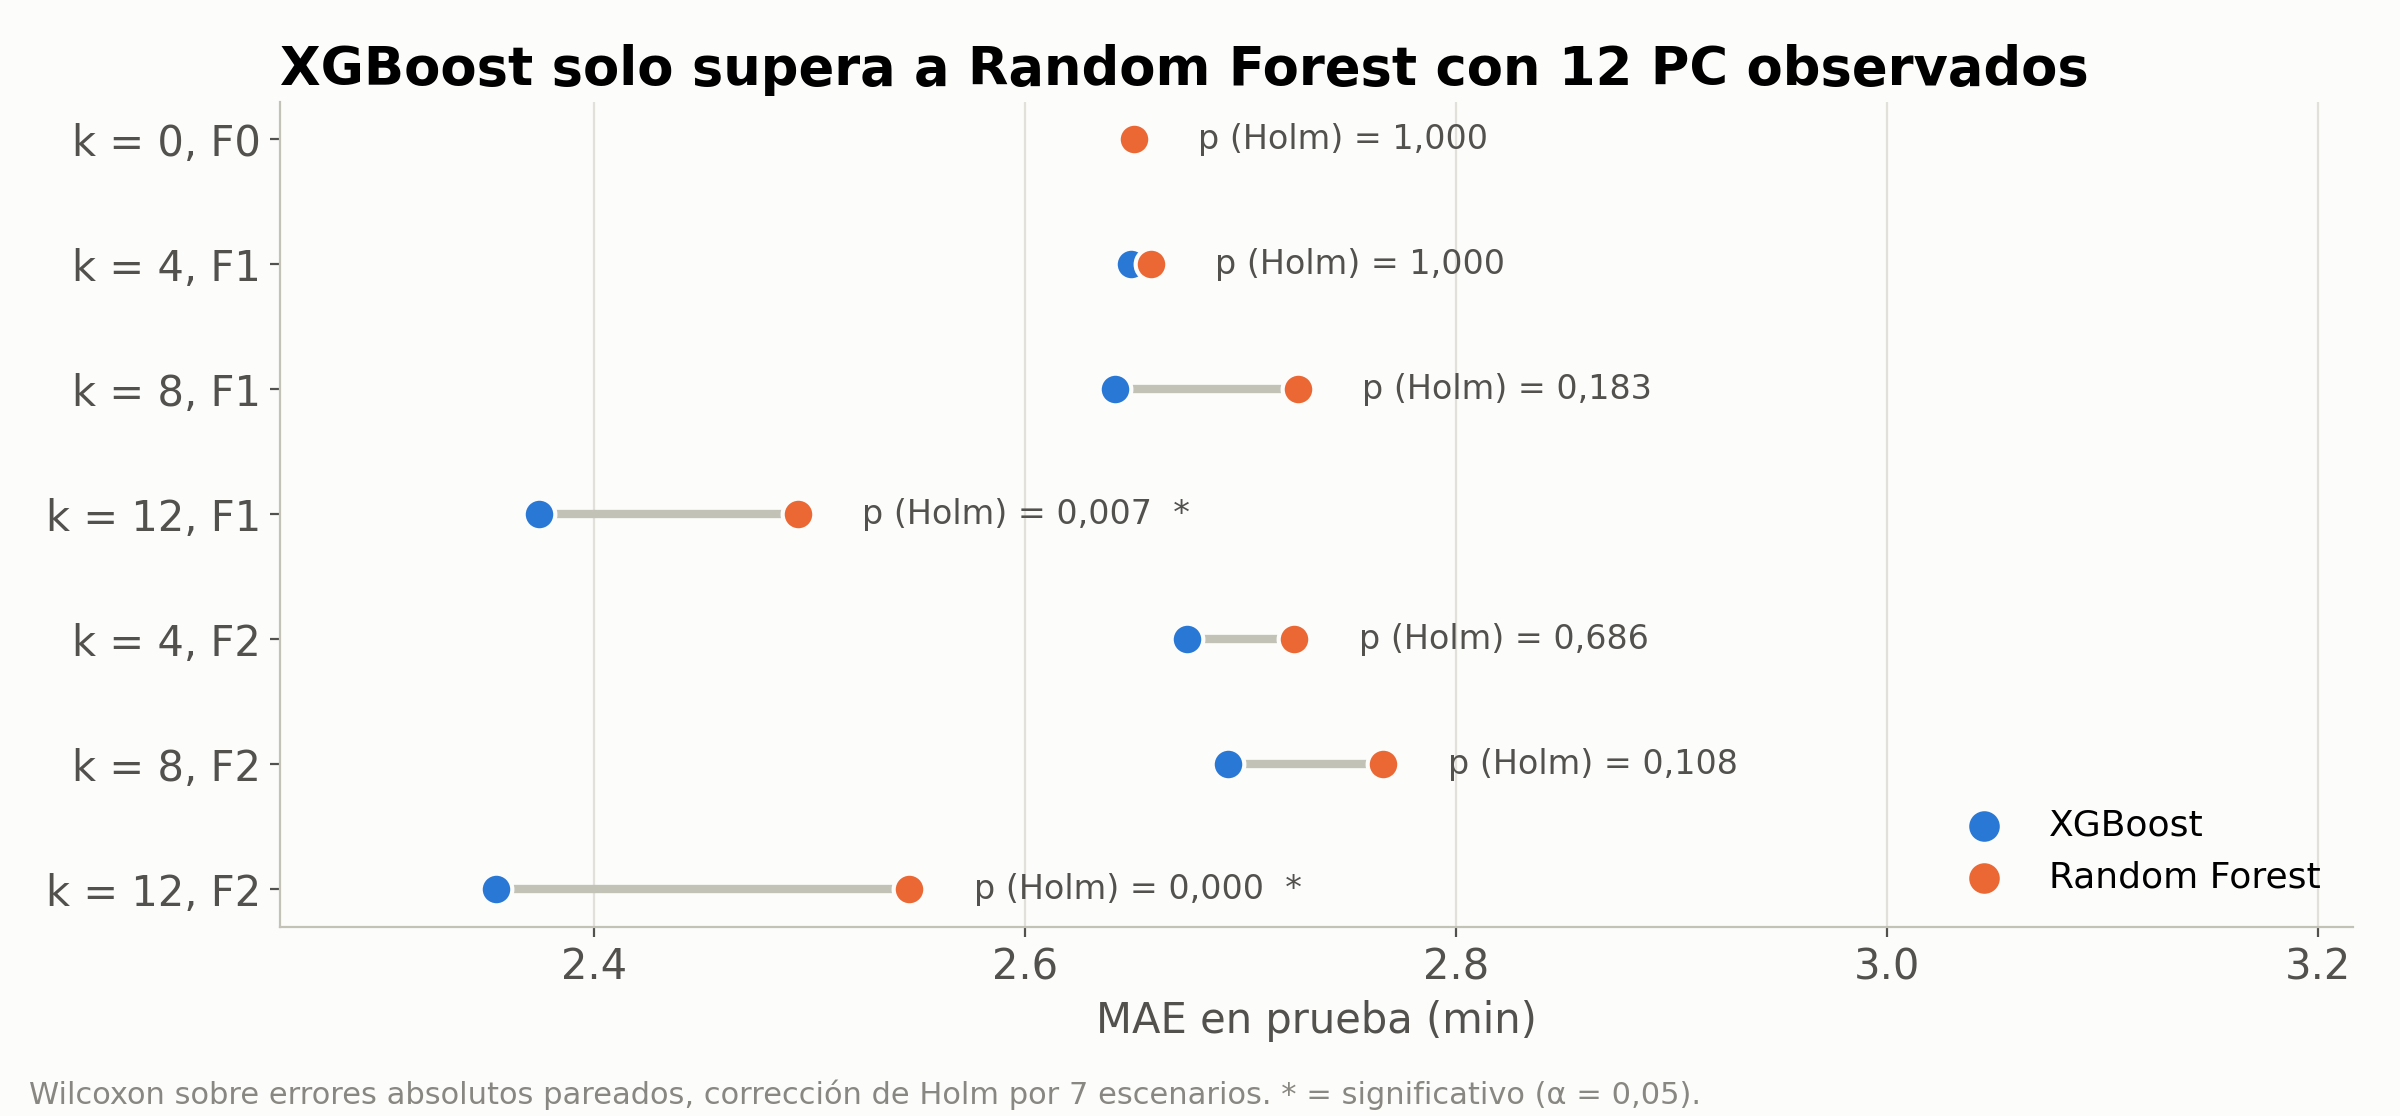

In [21]:
FIG("pres_17_xgb_vs_rf.png")

## 7. Mejora 3 — pesos por clase para recuperar "adelantado" (D4b)

Se multiplican las probabilidades de "adelantado" y "retrasado" por pesos (0,5 a 3,0) y se predice la clase de mayor probabilidad
ponderada. **Validación anidada:** los pesos se eligen con 3 pliegues y se evalúan en el cuarto, rotando; la regla D1 decide.

In [22]:
display(R("d4b_pesos_validacion.csv").round(3))
display(Markdown("**En prueba (solo se adopta si pasó D1 en validación)**")); display(R("d4b_pesos_test.csv").round(3))

,k,conjunto,modelo,F1_val_sin,F1_val_con,pliegues_ganados,acepta_D1,w_adelantado,w_retrasado,pesos_por_pliegue,p_mcnemar_test
0,0,F0,xgb,0.714,0.708,1,False,1.6,1.0,"[(np.float64(2.3), np.float64(1.0)), (np.float...",0.038
1,4,F1,rf,0.711,0.700,0,False,1.0,1.0,"[(np.float64(1.0), np.float64(1.0)), (np.float...",1.000
2,8,F1,xgb,0.724,0.711,1,False,0.9,1.1,"[(np.float64(2.0), np.float64(1.3)), (np.float...",0.388
3,12,F1,xgb,0.734,0.736,3,True,1.7,1.0,"[(np.float64(1.7), np.float64(1.0)), (np.float...",1.000
4,4,F2,xgb,0.708,0.686,0,False,1.0,1.0,"[(np.float64(2.3), np.float64(2.5)), (np.float...",1.000
5,8,F2,xgb,0.724,0.711,0,False,1.7,1.0,"[(np.float64(1.8), np.float64(1.0)), (np.float...",0.845
6,12,F2,xgb,0.728,0.720,1,False,1.0,1.2,"[(np.float64(1.6), np.float64(1.2)), (np.float...",0.180


**En prueba (solo se adopta si pasó D1 en validación)**

,k,conjunto,modelo,F1_macro,recall_retrasado,exactitud,exactitud_bal,sens_adel,espec_adel,sens_punt,espec_punt,sens_retr,espec_retr,PR_AUC,kappa
0,0,F0,xgb,0.740,0.770,0.780,0.722,0.541,0.968,0.855,0.670,0.770,0.923,0.818,0.595
1,0,F0,xgb+pesos,0.731,0.770,0.764,0.727,0.600,0.933,0.811,0.702,0.770,0.923,0.818,0.579
2,4,F1,rf,0.722,0.862,0.747,0.738,0.607,0.937,0.744,0.757,0.862,0.866,0.805,0.565
3,4,F1,rf+pesos,0.722,0.862,0.747,0.738,0.607,0.937,0.744,0.757,0.862,0.866,0.805,0.565
4,8,F1,xgb,0.732,0.787,0.770,0.715,0.519,0.979,0.840,0.670,0.787,0.899,0.812,0.580
5,8,F1,xgb+pesos,0.736,0.828,0.776,0.723,0.504,0.981,0.837,0.686,0.828,0.896,0.812,0.592
6,12,F1,xgb,0.751,0.828,0.790,0.736,0.526,0.976,0.855,0.699,0.828,0.913,0.826,0.617
7,12,F1,xgb+pesos,0.759,0.828,0.790,0.752,0.593,0.961,0.835,0.728,0.828,0.913,0.826,0.624
8,4,F2,xgb,0.739,0.810,0.778,0.726,0.526,0.970,0.842,0.689,0.810,0.909,0.806,0.597
9,4,F2,xgb+pesos,0.739,0.810,0.778,0.726,0.526,0.970,0.842,0.689,0.810,0.909,0.806,0.597


## 8. Análisis de sensibilidad de los umbrales de clase

In [23]:
s = res[(res.tarea == "clf") & (res.modelo.isin(["xgb", "B2 histórico"])) & (res.k == 0)]
s[["umbral", "modelo", "exactitud", "exactitud_bal", "F1_macro", "kappa", "sens_adel", "sens_retr"]].round(3)

,umbral,modelo,exactitud,exactitud_bal,F1_macro,kappa,sens_adel,sens_retr
14,amplio,xgb,0.832,0.829,0.752,0.601,0.836,0.818
24,cao,xgb,0.780,0.722,0.740,0.595,0.541,0.770
64,cao,B2 histórico,0.592,0.333,0.248,0.000,0.000,0.000
89,amplio,B2 histórico,0.788,0.333,0.294,0.000,0.000,0.000


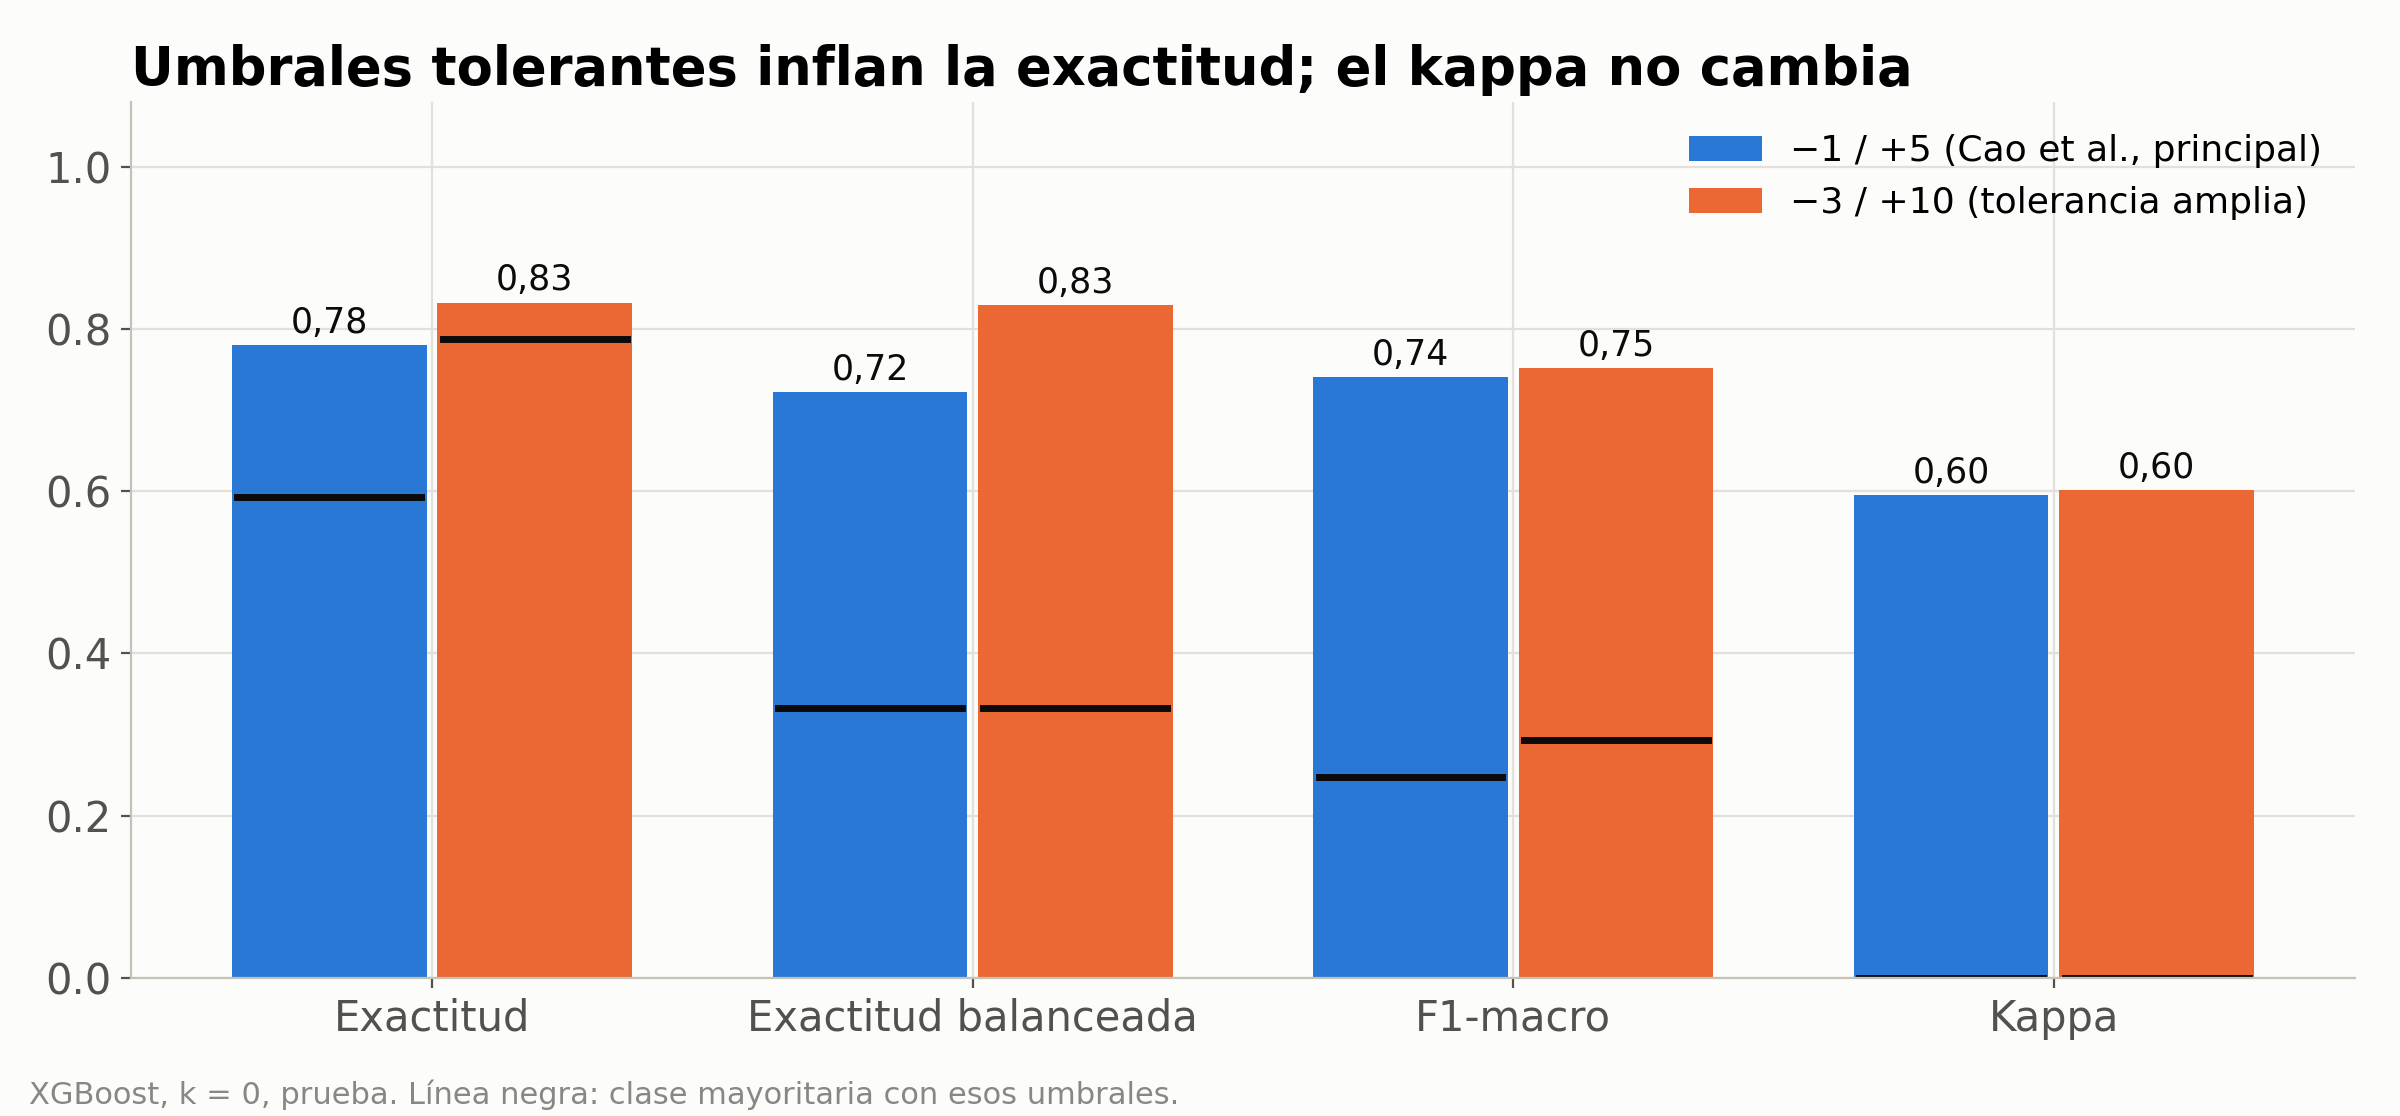

In [24]:
FIG("pres_16_sensibilidad_umbrales.png")

## 9. Interpretación: importancia por permutación y SHAP

In [25]:
imp = R("importancia_permutacion.csv")
display(imp.sort_values("media", ascending=False).groupby(["tarea", "k", "conjunto"]).head(6).round(4))

,variable,media,std,tarea,modelo,k,conjunto
0,hora_salida,3.9730,0.0915,reg,xgb,0,F0
51,hora_salida,2.3441,0.0949,reg,xgb,12,F1
5,hora_salida,2.2723,0.0966,reg,xgb,12,F2
1,dia_semana,1.6010,0.0598,reg,xgb,0,F0
67,d12,1.3702,0.0743,reg,xgb,12,F1
21,d12,1.2625,0.0697,reg,xgb,12,F2
52,dia_semana,0.4445,0.0330,reg,xgb,12,F1
6,dia_semana,0.4174,0.0324,reg,xgb,12,F2
3,dur_prog,0.2398,0.0383,reg,xgb,0,F0
4,vehiculo,0.1503,0.0249,reg,xgb,0,F0


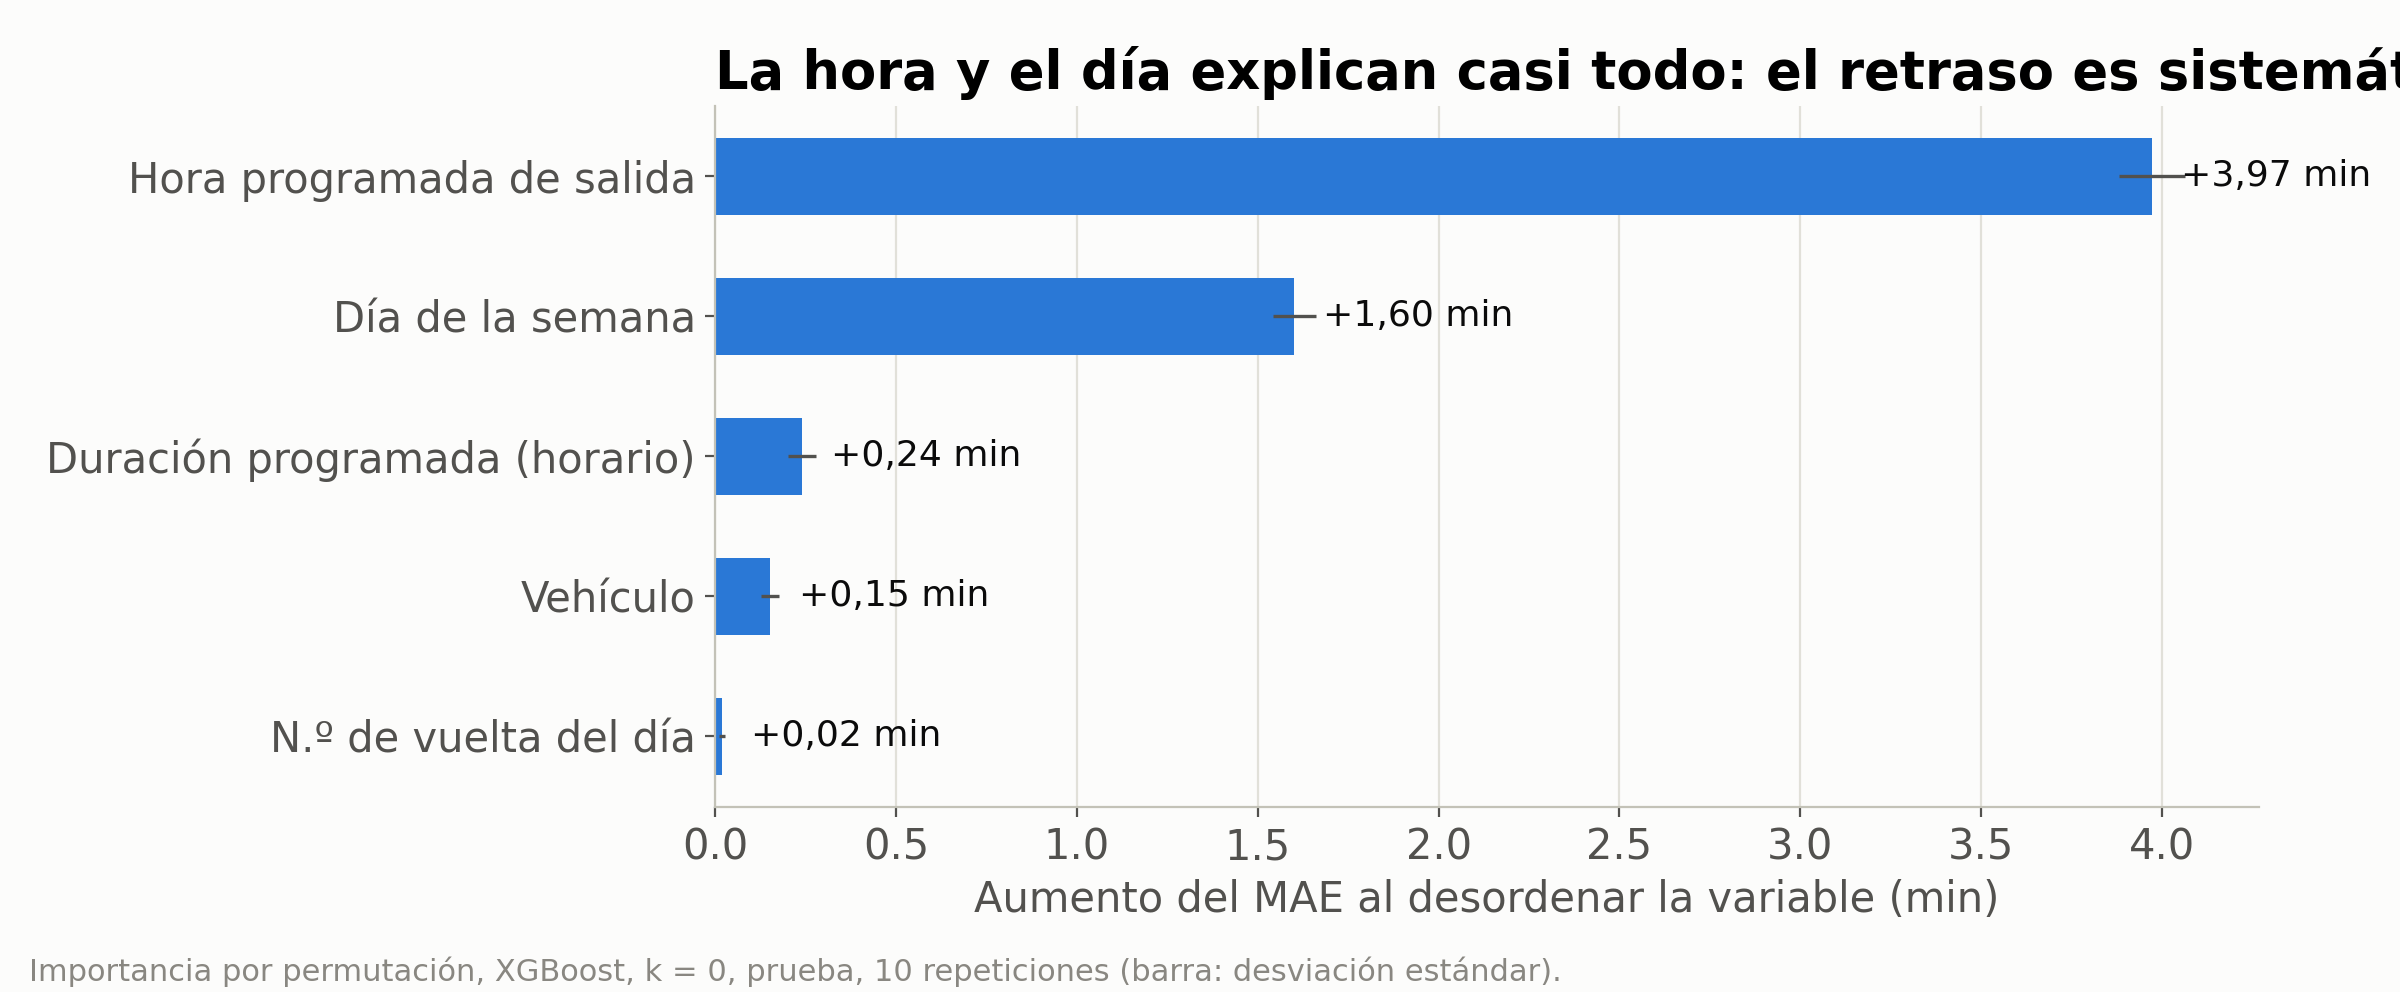

In [26]:
FIG("pres_18_importancia.png")

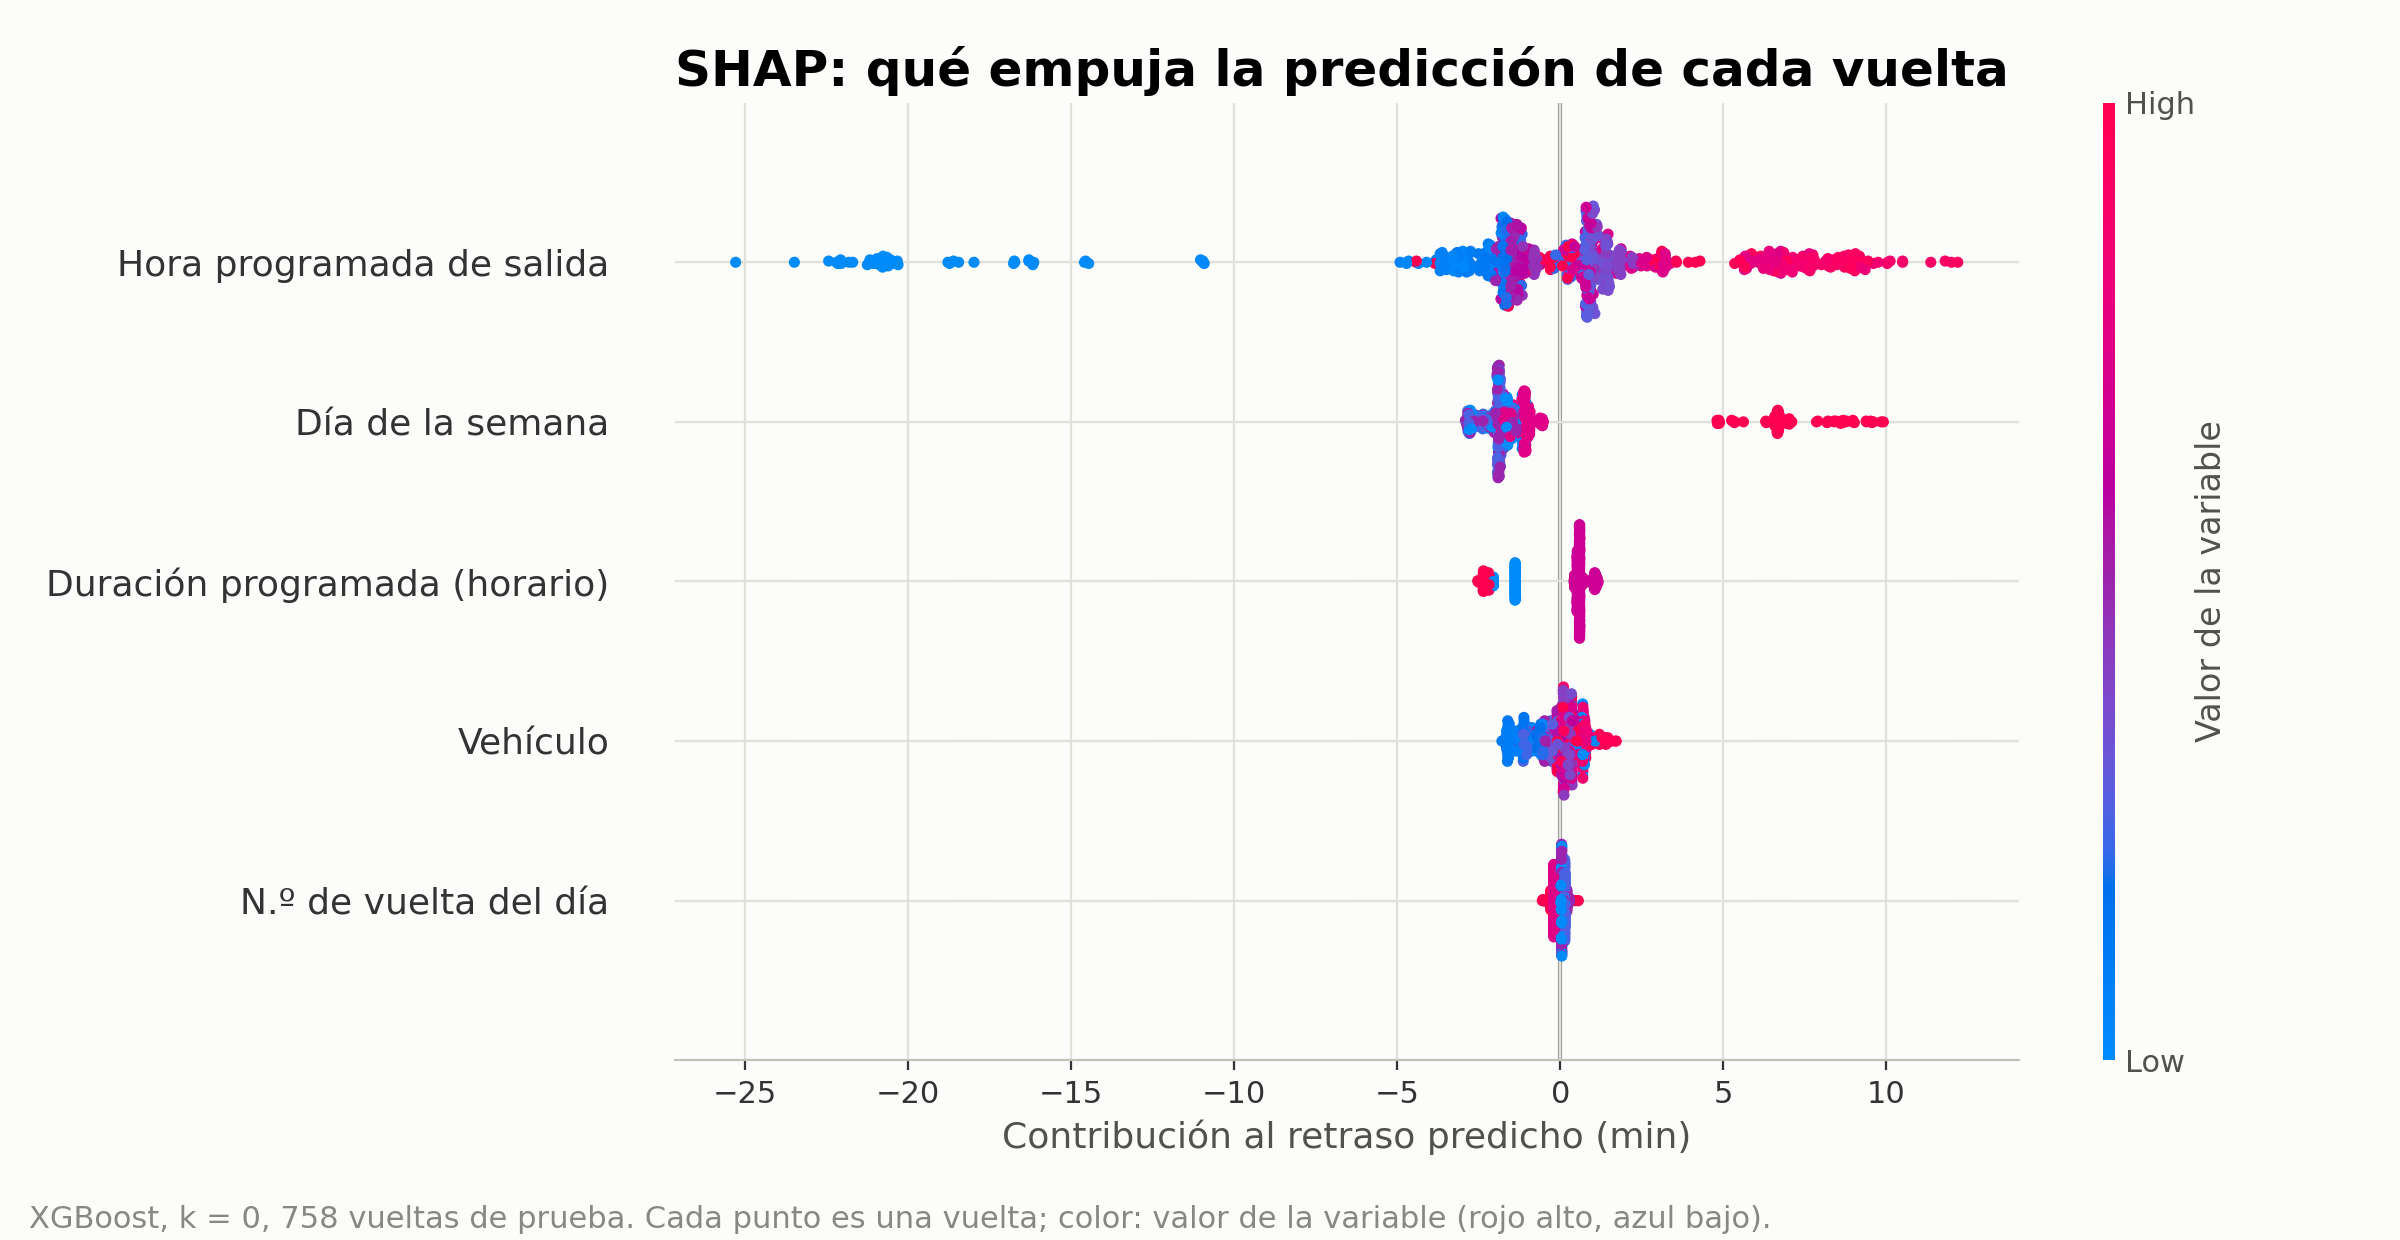

In [27]:
FIG("pres_19_shap_resumen.png")

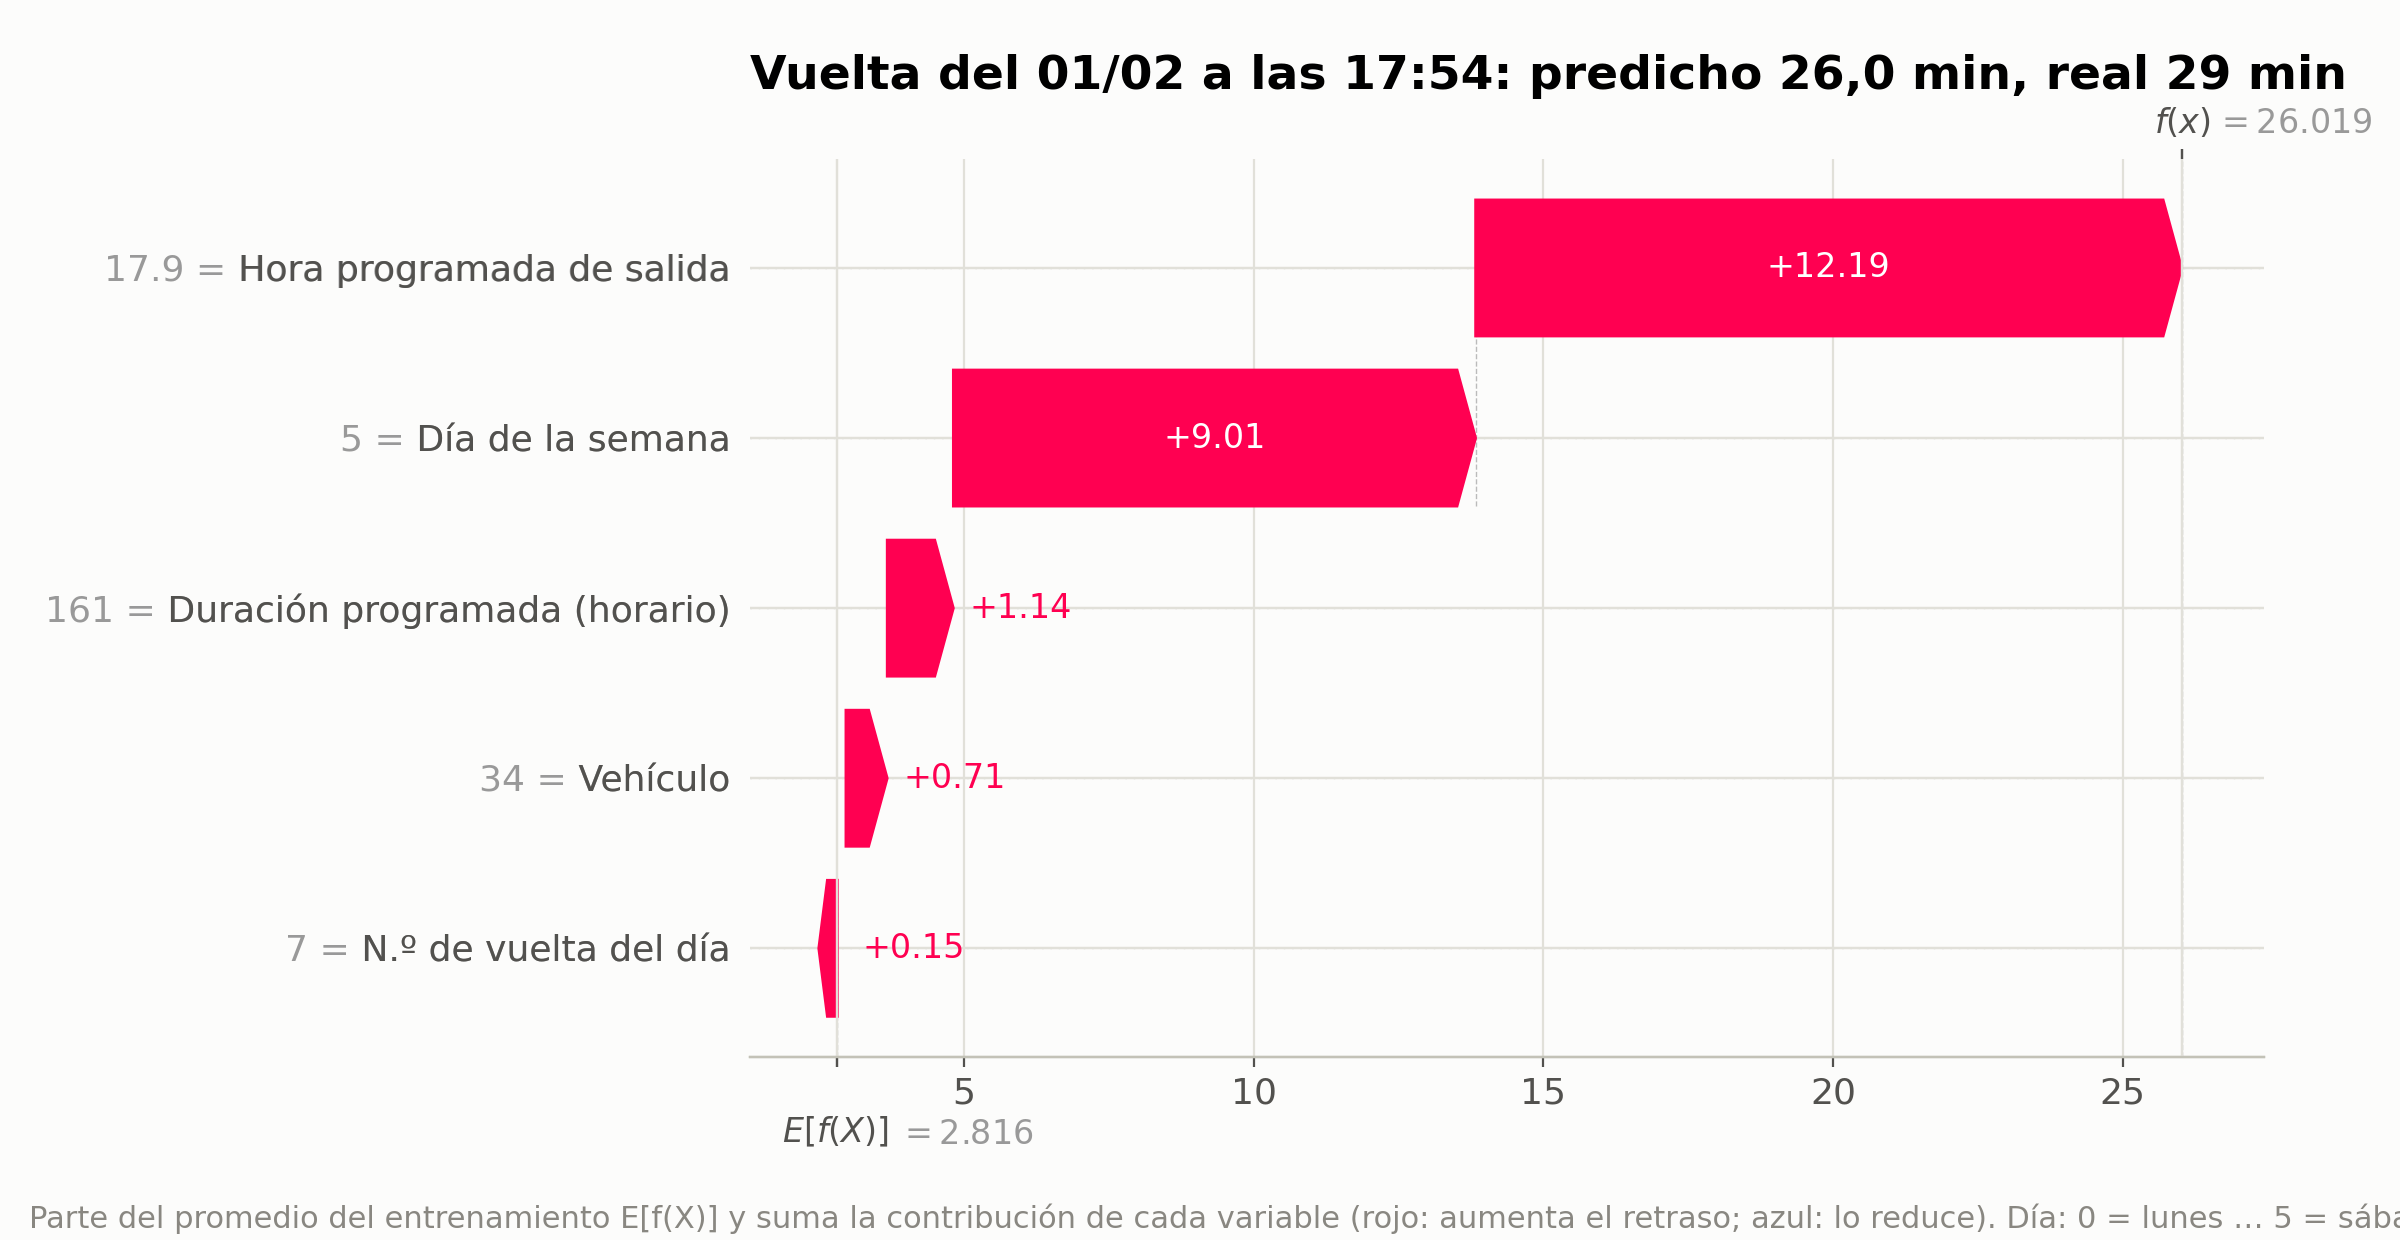

In [28]:
FIG("pres_20_shap_sabado.png")

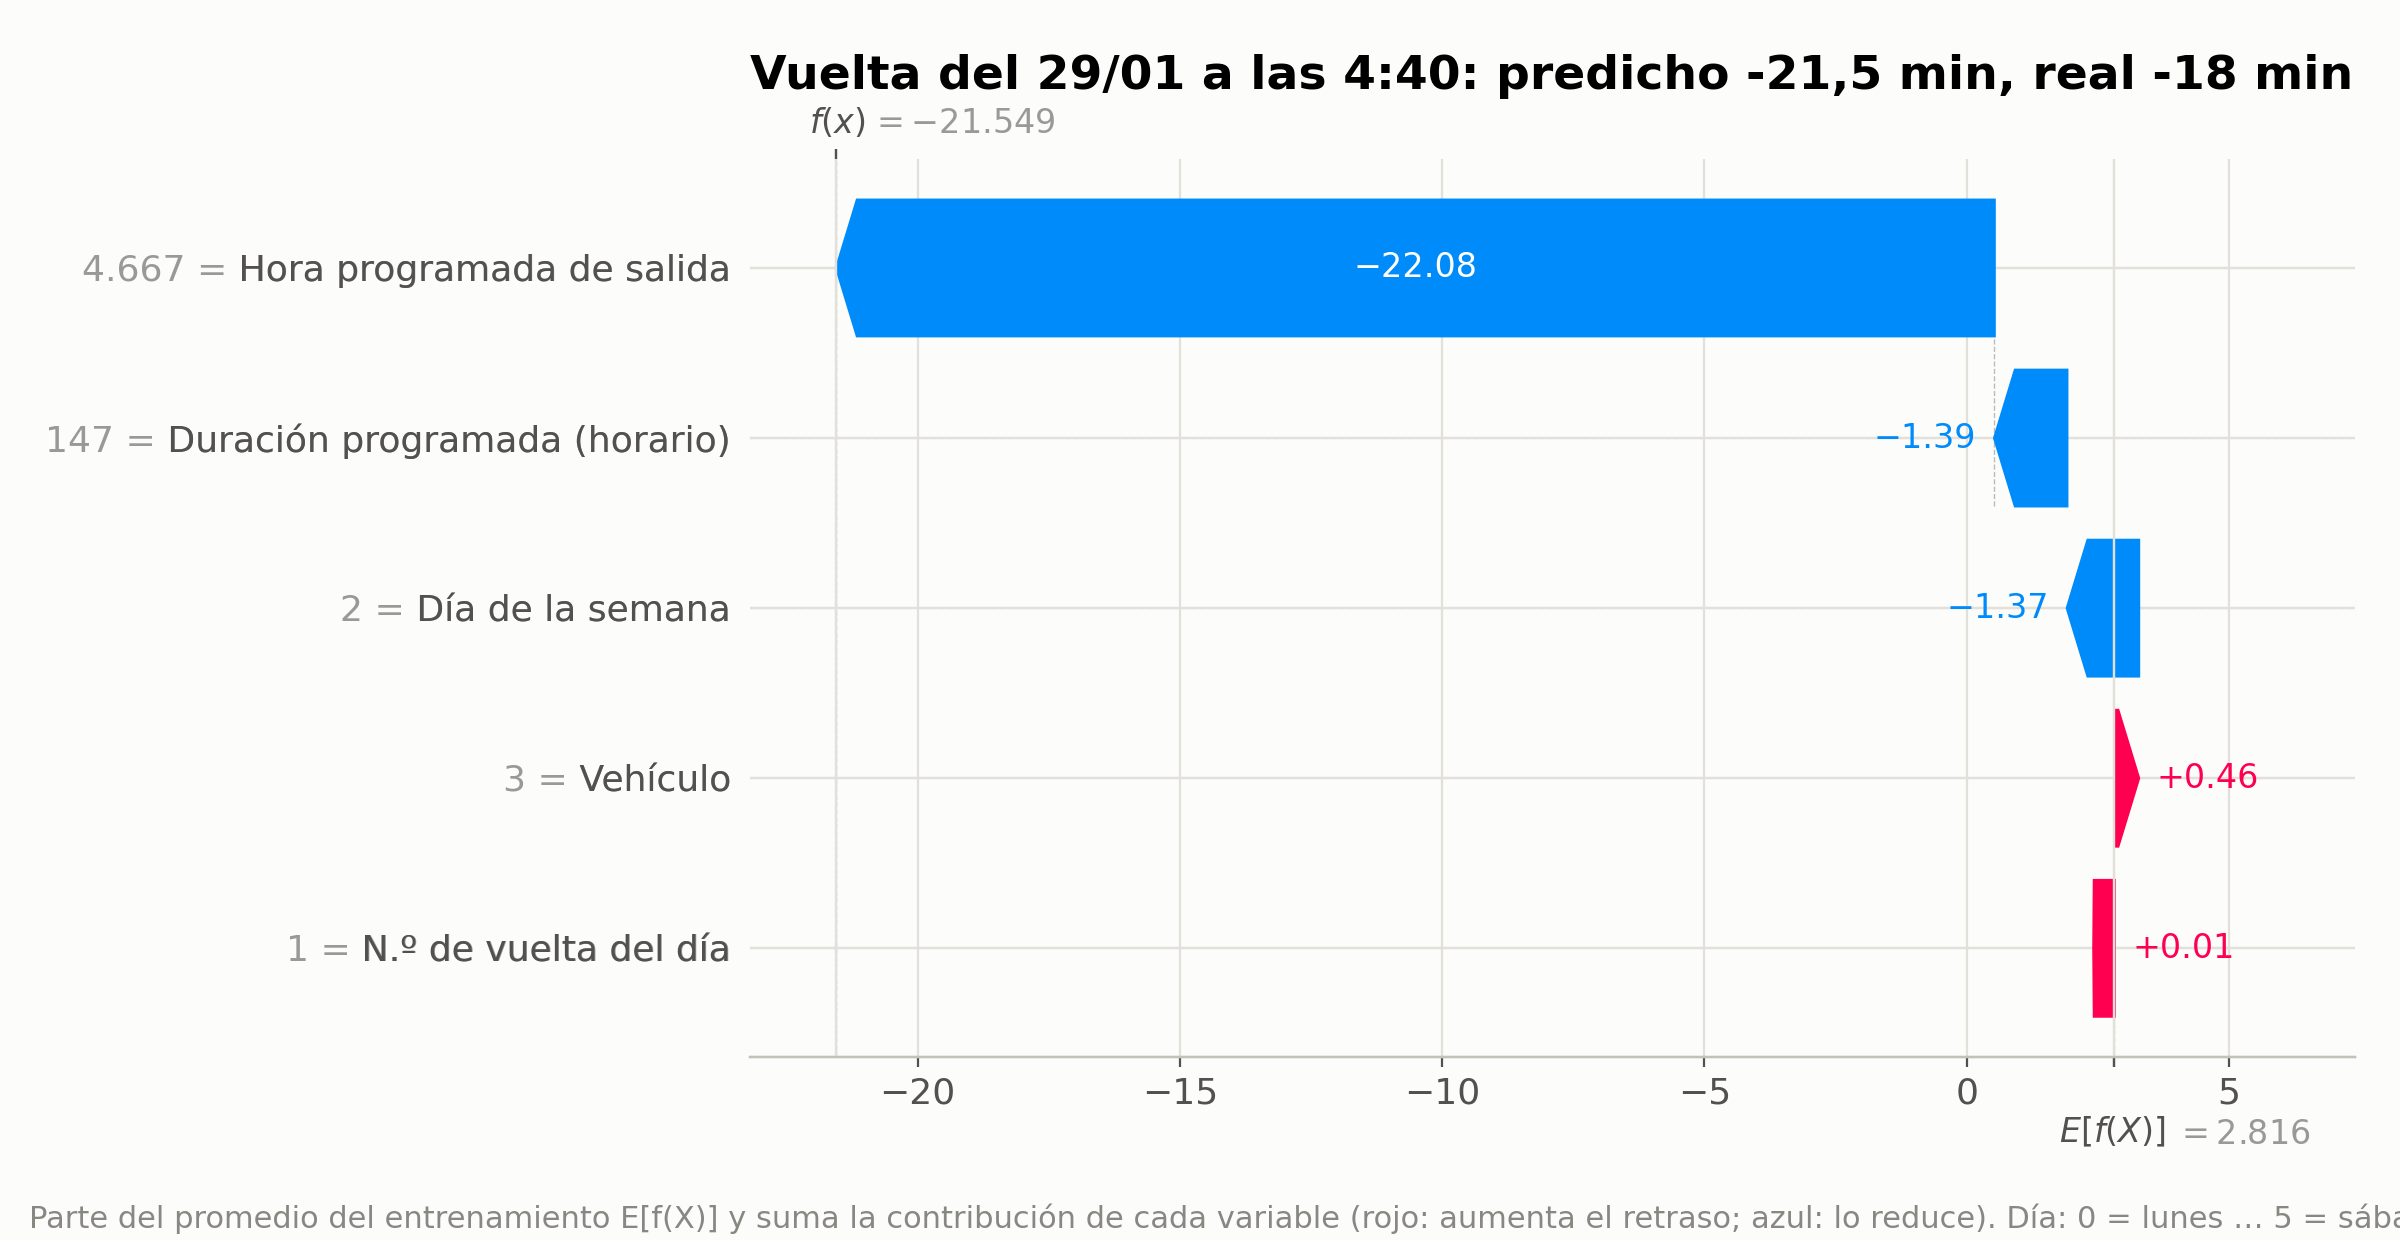

In [29]:
FIG("pres_20_shap_madrugada.png")

## 10. Archivos generados

* `resultados/`: tablas en CSV (validación, prueba, pruebas estadísticas, predicciones por vuelta).
* `modelos/`: modelos XGBoost entrenados con el desarrollo (`joblib`), para la demo.
* `fig/`: gráficos de la presentación (`pres_*.png`).